# Week 5 - Part A: nine charts broken by the encoding or the geography

Every case is rebuilt from the recipe first and has to hit the self-check number (each one is an `assert`, so the notebook stops if a rebuild is off).
Then for each one: the conclusion the chart invites, the first objection I thought of and why the data rules it out, the channel or boundary that is lying with the number that proves it, and the redesign plotted.

All data is synthetic course data for CDB601220 (Week 5). Maps use `geolib` (no geopandas) and are drawn in Lambert cylindrical equal-area.

In [1]:
import sys
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

# Works both as a notebook (opened from week5/) and as a script (week5/submission/x.py)
try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import geolib as gl
from vizlib import PALETTE, save_fig, style_defaults, lie_factor, lie_verdict

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)

style_defaults()
warnings.filterwarnings("ignore", category=FutureWarning)

BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK, SOFT = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]   # file order

FEATS = gl.read_geojson(DATA / "districts.geojson")
LAT_TS = gl._collection_lat_ts(FEATS)
BOUNDS = (f"Boundaries: districts.geojson, fictional federation (course file, Week 5, 2026). "
          f"Lambert cylindrical equal-area, true scale {LAT_TS:.1f}°N.")


def src(file, extra=""):
    note = f"Source: synthetic course data, CDB601220 Week 5 ({file}). Chart: Syed Sami Ullah."
    return note + ("\n" + extra if extra else "")


def save(fig, name, file, extra=""):
    save_fig(fig, CHARTS / name, note=src(file, extra))
    show()


def check_join(feats, df, key="code"):
    """Count the rows that fail to join, both ways, before anything is coloured."""
    geo, tab = {f[key] for f in feats}, set(df[key])
    print(f"join on {key}: {len(geo & tab)} matched, {len(tab - geo)} table rows with no polygon, "
          f"{len(geo - tab)} polygons with no row")
    return len(tab - geo), len(geo - tab)


def corr_chain(df, cols):
    """geolib.corr_chain's greedy rule (slide 24). The toolkit version calls np.fill_diagonal on
    DataFrame.values, which pandas 3 hands back read-only, so it crashes on my install. Same rule here."""
    try:
        return gl.corr_chain(df, cols)
    except ValueError:
        r = df[list(cols)].corr().abs().to_numpy(copy=True)
        np.fill_diagonal(r, 0.0)
        i, j = np.unravel_index(np.argmax(r), r.shape)
        order = [cols[i], cols[j]]
        while len(order) < len(cols):
            rest = [c for c in cols if c not in order]
            order.append(max(rest, key=lambda c: r[cols.index(order[-1]), cols.index(c)]))
        return order


def crossings(a, b):
    """How many pairs of lines cross between two adjacent PCP axes (= discordant pairs)."""
    a, b = np.asarray(a), np.asarray(b)
    da, db = a[:, None] - a[None, :], b[:, None] - b[None, :]
    return int(((da * db) < 0).sum() // 2)


hi = pd.read_csv(DATA / "health_indicators.csv")
dh = pd.read_csv(DATA / "district_health.csv")
dh["rate"] = dh.cases / dh.population * 1e5

---
## Case 1 · "Population and healthcare access are unrelated - the large countries are spread right across the range"
Recipe: `ax.scatter(df.gdp_pc, df.healthcare_access, s=df.pop_m**2)` on a log x axis.

pop_m 0.6 to 353.4 M = 589x
s = pop**2: largest mark 589x the smallest ACROSS and 346,921x in AREA
9 countries under 2.0 M get s < 4 pt^2 (under 2 pt across); strictly below 1 pt^2: 3


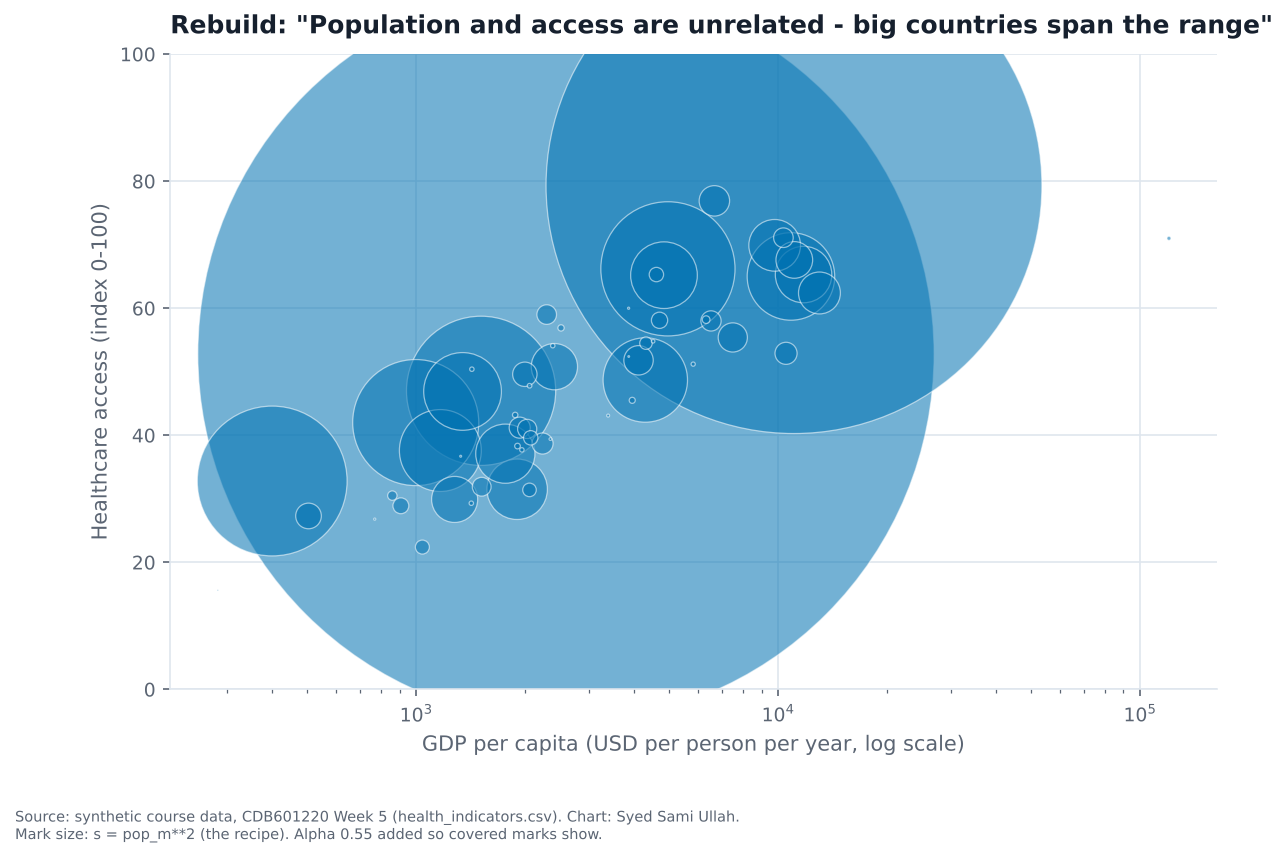

marks whose centre sits under a bigger mark: 57 of 60


In [2]:
s_bad = hi.pop_m ** 2
area_ratio = s_bad.max() / s_bad.min()
diam_ratio = np.sqrt(area_ratio)            # marker diameter in points = sqrt(s)
small = hi.pop_m < 2.0

assert len(hi) == 60
assert round(diam_ratio) == 589 and round(hi.pop_m.max() / hi.pop_m.min()) == 589
assert small.sum() == 9 and (s_bad[small] < 4).all()
print(f"pop_m {hi.pop_m.min()} to {hi.pop_m.max()} M = {hi.pop_m.max() / hi.pop_m.min():.0f}x")
print(f"s = pop**2: largest mark {diam_ratio:.0f}x the smallest ACROSS and {area_ratio:,.0f}x in AREA")
print(f"{small.sum()} countries under 2.0 M get s < 4 pt^2 (under 2 pt across); strictly below 1 pt^2: {(s_bad < 1).sum()}")


def draw_bubbles(ax, s, alpha=0.55):
    order = np.argsort(-s.to_numpy())            # big first so small sit on top
    sc = ax.scatter(hi.gdp_pc.iloc[order], hi.healthcare_access.iloc[order], s=s.iloc[order],
                    color=BLUE, alpha=alpha, edgecolor="white", linewidth=0.6)
    ax.set_xscale("log")
    ax.set_xlabel("GDP per capita (USD per person per year, log scale)")
    ax.set_ylabel("Healthcare access (index 0-100)")
    return sc


def hidden_centres(fig, ax, s):
    """How many marks have their centre underneath a BIGGER mark, measured on the drawn figure."""
    fig.canvas.draw()
    xy = ax.transData.transform(np.column_stack([hi.gdp_pc, hi.healthcare_access]))
    r = np.sqrt(s.to_numpy()) / 2 * fig.dpi / 72          # radius in pixels
    d = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])
    covered = (d < r[None, :]) & (r[None, :] > r[:, None])
    return int(covered.any(axis=1).sum())


fig, ax = plt.subplots(figsize=(9, 5.5))
draw_bubbles(ax, s_bad)
ax.set_ylim(0, 100)
ax.set_title('Rebuild: "Population and access are unrelated - big countries span the range"')
n_hidden_bad = hidden_centres(fig, ax, s_bad)
save(fig, "partA_case01_rebuild.png", "health_indicators.csv", "Mark size: s = pop_m**2 (the recipe). Alpha 0.55 added so covered marks show.")
print(f"marks whose centre sits under a bigger mark: {n_hidden_bad} of 60")

**What this chart shows.** Two huge blobs (Wessant and Vornath) take over the middle and top of the chart and a few mid-sized ones sit around them. The small countries are specks you can barely find.

In [3]:
big = hi.nlargest(4, "pop_m")[["country", "pop_m", "healthcare_access"]]
print(big.to_string(index=False))
w, v = hi.set_index("country").loc[["Wessant", "Vornath"], "pop_m"]
print(f"Wessant / Vornath: {w / v:.2f}x the people, drawn {(w / v) ** 2:.2f}x the area")
lf, de, ge = lie_factor(hi.pop_m.min(), hi.pop_m.max(), hi.pop_m.min(), hi.pop_m.max(), ink_dimension=2)
print(f"Lie Factor smallest -> largest (ink_dimension=2): {lf:,.0f}  ({lie_verdict(lf)})")
ink = s_bad / s_bad.sum()
print(f"share of all ink in the two biggest marks: {ink.nlargest(2).sum():.1%} (honest area: {hi.pop_m.nlargest(2).sum() / hi.pop_m.sum():.1%})")
r_pa, p_pa = stats.pearsonr(hi.pop_m, hi.healthcare_access)
rho_pa = stats.spearmanr(hi.pop_m, hi.healthcare_access)[0]
print(f"r(pop, access) = {r_pa:+.3f} (p = {p_pa:.2f}), Spearman {rho_pa:+.3f}")
r_ga = np.corrcoef(np.log10(hi.gdp_pc), hi.healthcare_access)[0, 1]
print(f"r(log10 gdp, access) = {r_ga:+.3f}  <- the pattern the blobs sit on top of")

 country  pop_m  healthcare_access
 Wessant  353.4               52.8
 Vornath  238.0               79.3
Tarrowin   71.9               32.8
  Galvia   71.6               47.0
Wessant / Vornath: 1.48x the people, drawn 2.20x the area
Lie Factor smallest -> largest (ink_dimension=2): 590  (exaggerates 590.00x)
share of all ink in the two biggest marks: 84.9% (honest area: 40.0%)
r(pop, access) = +0.211 (p = 0.11), Spearman +0.222
r(log10 gdp, access) = +0.834  <- the pattern the blobs sit on top of


- **Conclusion it invites:** country size has nothing to do with healthcare access, because the big marks are scattered from the bottom to the top.
- **Decoy:** my first thought was plain overplotting, fix it with transparency. Ruled out: alpha only lets you see *through* the marks, it doesn't change their sizes. Wessant has 1.48× Vornath's people and is still drawn 2.20× the area at any alpha.
- **Mechanism:** the value drives the **radius**, not the area. `s` in `ax.scatter` is already an area (points²), so `s=pop**2` makes the diameter grow with population and the area with population squared. Population spans 589×, so the largest mark is 589× the smallest *across* and 346,921× in area (Lie Factor 590). The two biggest marks hold 85% of all the ink while having 40% of the people, 57 of the 60 marks have their centre under a bigger mark, and the 9 countries under 2.0 M are under 2 pt across. "The large countries" ends up meaning two blobs. (The brief's self-check says "589× the area"; on my rebuild 589× is the diameter and the area ratio is 589².)
- What the data actually says: r(pop, access) = +0.21 (p = 0.11), so size and access are only weakly related. The chart happens to point near the right answer, but it can't show it, and it hides the strong pattern underneath: access rises with log GDP (r = +0.83).

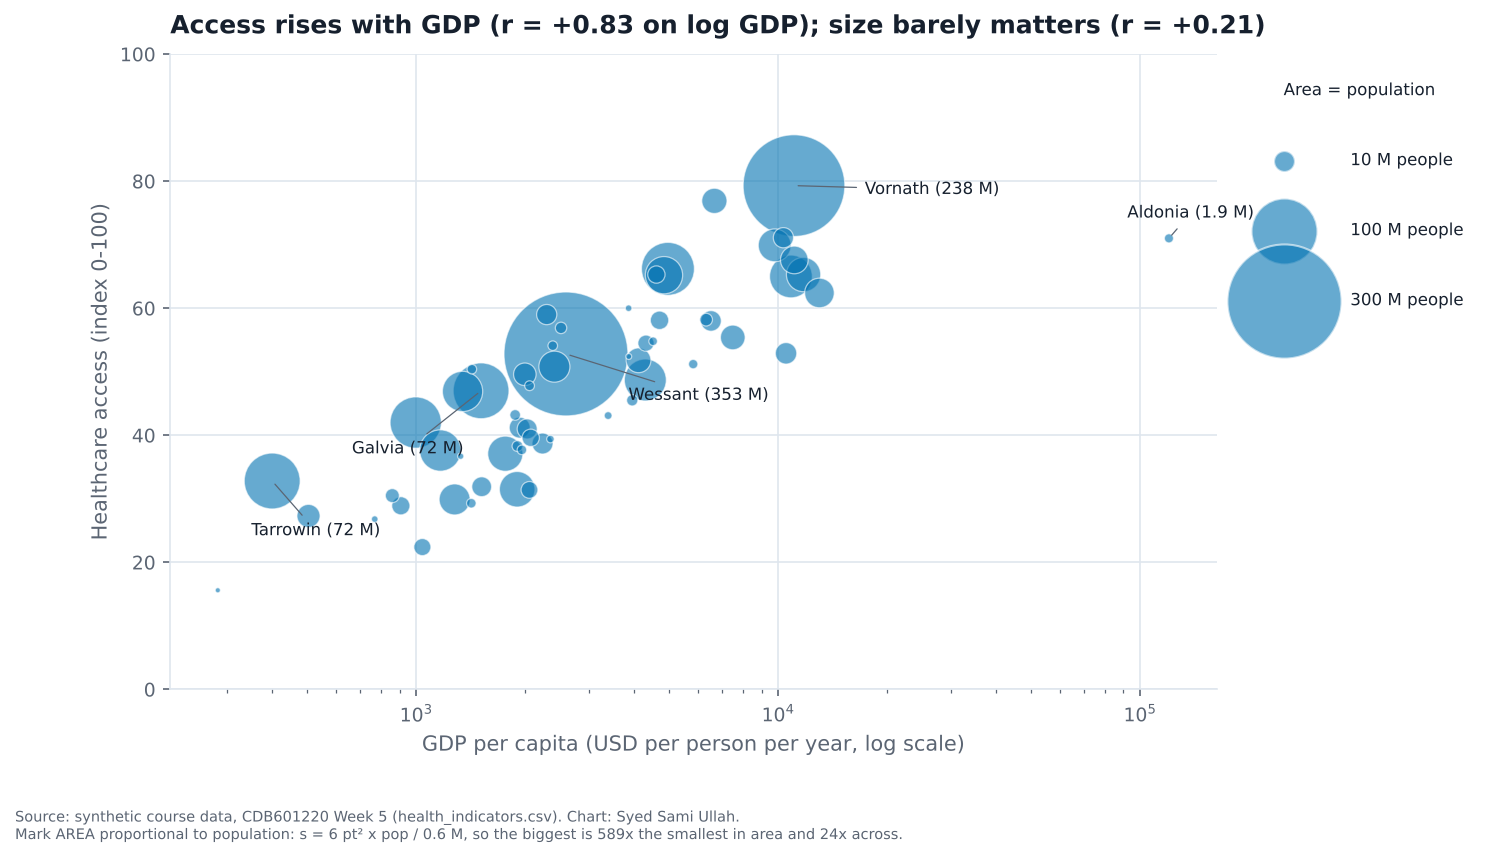

marks with centre under a bigger mark now: 23 of 60 (was 57)


In [4]:
SIZE_LO = 6.0                                        # pt^2 for the smallest country (Part B1)
s_ok = SIZE_LO * hi.pop_m / hi.pop_m.min()           # area proportional to population
assert np.allclose(s_ok / hi.pop_m, s_ok.iloc[0] / hi.pop_m.iloc[0])
fig, ax = plt.subplots(figsize=(9, 5.5))
draw_bubbles(ax, s_ok, alpha=0.6)
ax.set_ylim(0, 100)
for name, off in [("Wessant", (30, -22)), ("Vornath", (34, -4)), ("Tarrowin", (-10, -26)), ("Galvia", (-62, -30)),
                  ("Aldonia", (-20, 10))]:
    row = hi.set_index("country").loc[name]
    ax.annotate(f"{name} ({row.pop_m:.1f} M)" if row.pop_m < 10 else f"{name} ({row.pop_m:.0f} M)",
                (row.gdp_pc, row.healthcare_access), xytext=off, textcoords="offset points", fontsize=8, color=INK,
                arrowprops=dict(arrowstyle="-", color=SOFT, lw=0.6))
for v in [10, 100, 300]:
    ax.scatter([], [], s=SIZE_LO * v / hi.pop_m.min(), color=BLUE, alpha=0.6, edgecolor="white", label=f"{v} M people")
ax.legend(title="Area = population", loc="upper left", bbox_to_anchor=(1.01, 1.0), labelspacing=3.2, borderpad=1.2, handletextpad=2.2, handlelength=3.5,
          fontsize=8, title_fontsize=8)
n_hidden_ok = hidden_centres(fig, ax, s_ok)
ax.set_title(f"Access rises with GDP (r = +{r_ga:.2f} on log GDP); size barely matters (r = +{r_pa:.2f})")
save(fig, "partA_case01_redesign.png", "health_indicators.csv",
     f"Mark AREA proportional to population: s = {SIZE_LO:g} pt² x pop / 0.6 M, so the biggest is 589x the smallest in area and 24x across.")
print(f"marks with centre under a bigger mark now: {n_hidden_ok} of 60 (was {n_hidden_bad})")

**What the redesign shows.** With area proportional to people and a size legend, Wessant is a big mark but not a blanket, every small country is visible, and the real story comes out: access climbs with GDP. Size is spread across access, but weakly tilted upward.

---
## Case 2 · "The outbreak is concentrated in the three districts around the capital"
Recipe: join on `code`, colour districts by `cases` with five natural breaks and a sequential blue ramp, list the top three.

join on code: 24 matched, 0 table rows with no polygon, 0 polygons with no row


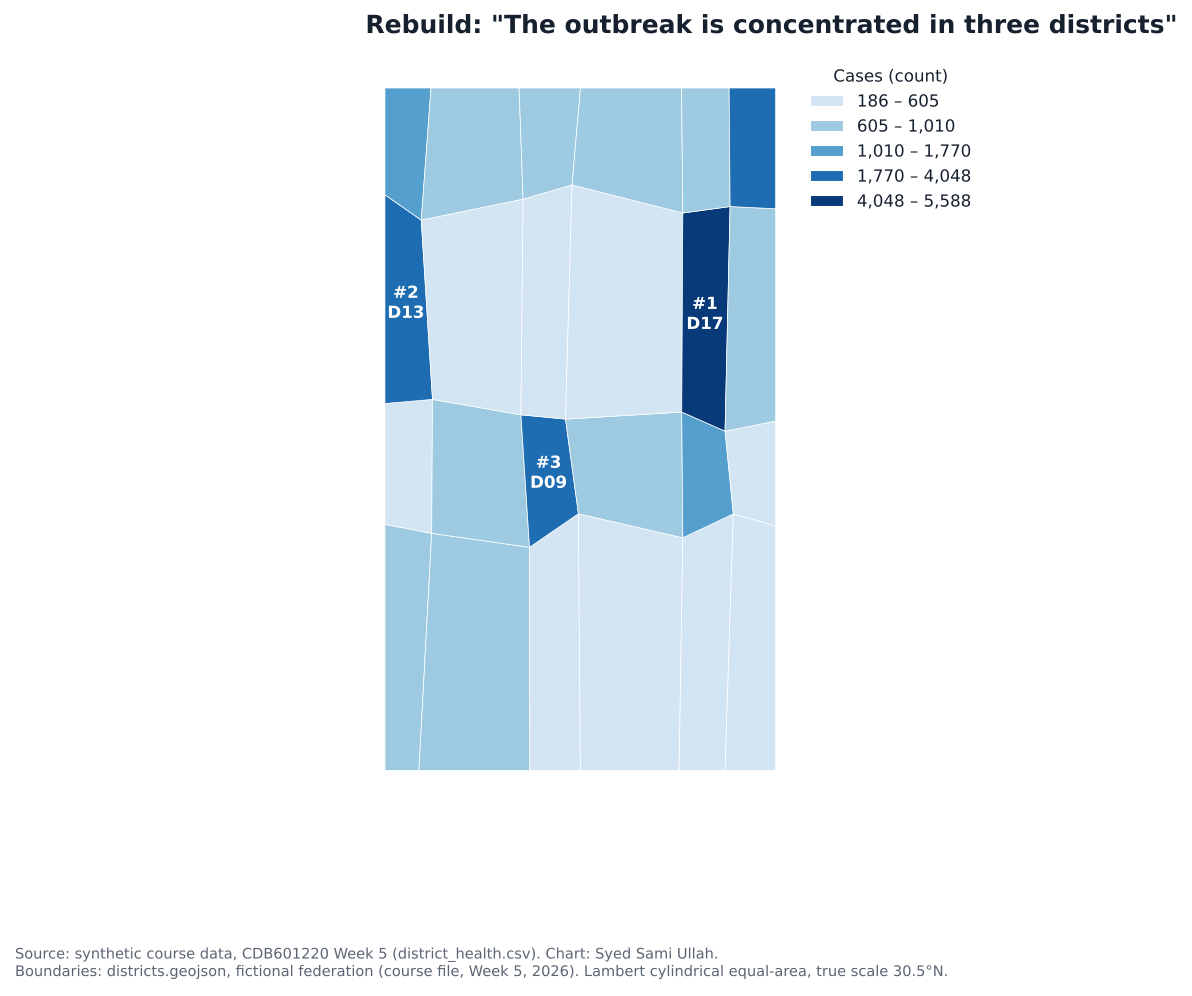

natural breaks on cases: [186, 605, 1010, 1770, 4048, 5588]


In [5]:
miss_tab, miss_geo = check_join(FEATS, dh)
top_count = dh.nlargest(3, "cases").code.tolist()
assert len(dh) == 24 and miss_tab == 0 and miss_geo == 0
assert dh.cases.sum() == 30_564 and dh.population.sum() == 57_857_000
assert top_count == ["D17", "D13", "D09"]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
edges = gl.choropleth(ax, FEATS, dict(zip(dh.code, dh.cases)), "natural", 5, legend_title="Cases (count)")
xy = {f["code"]: gl.equal_area_xy(*gl.representative_point(f["ring"]), lat_ts=LAT_TS) for f in FEATS}
for i, c in enumerate(top_count, 1):
    ax.annotate(f"#{i}\n{c}", xy[c], ha="center", va="center", fontsize=8, color="white", fontweight="bold")
ax.set_title('Rebuild: "The outbreak is concentrated in three districts"')
save(fig, "partA_case02_rebuild.png", "district_health.csv", BOUNDS)
print("natural breaks on cases:", [round(e) for e in edges])

**What this chart shows.** Three dark districts (D17, D13, D09) with the rest fading to pale blue. It reads like a clear hotspot, and the legend says only "cases".

In [6]:
r_cp = dh.cases.corr(dh.population)
r_rp = dh.rate.corr(dh.population)
top_rate = dh.nlargest(3, "rate").code.tolist()
pooled = dh.cases.sum() / dh.population.sum() * 1e5
print(f"r(cases, population) = {r_cp:+.3f}   r(rate, population) = {r_rp:+.3f}")
print("top 3 by count:", top_count, "| top 3 by rate:", top_rate, "| overlap:", len(set(top_count) & set(top_rate)))
print(dh.set_index("code").loc[top_count + top_rate, ["district", "cases", "population", "rate", "area_km2"]].round(1).to_string())
dh["area_rank"] = dh.area_km2.rank(ascending=False).astype(int)
print(f"r(cases, area) = {dh.cases.corr(dh.area_km2):+.3f}; area rank of the top 3 by count (1 = largest):",
      dh.set_index("code").loc[top_count, "area_rank"].tolist())
print(f"pooled national rate: {pooled:.1f} per 100,000")
assert round(r_cp, 3) == 0.986 and abs(r_rp) < 0.001 and top_rate == ["D19", "D20", "D21"]

r(cases, population) = +0.986   r(rate, population) = -0.000
top 3 by count: ['D17', 'D13', 'D09'] | top 3 by rate: ['D19', 'D20', 'D21'] | overlap: 0
        district  cases  population  rate  area_km2
code                                               
D17      Qilabad   5588    10966000  51.0   37007.5
D13     Mehrabad   4048     6327000  64.0   31089.4
D09     Ilyaspur   3437     6886000  49.9   21034.9
D19   Sibbi East   1381     1806000  76.5   19166.5
D20       Tarmak    994     1340000  74.2   44308.6
D21       Ushkan    744     1081000  68.8   22025.3
r(cases, area) = -0.351; area rank of the top 3 by count (1 = largest): [15, 16, 21]
pooled national rate: 52.8 per 100,000


- **Conclusion it invites:** three districts are where the outbreak is, so that's where the response should go.
- **Decoy:** my first thought was that the three are just the biggest districts, so they have more land to catch cases. Ruled out: they rank 15th, 16th and 21st of 24 by area, and r(cases, area) is −0.35. Land isn't the driver.
- **Mechanism:** the colour carries a **raw count**, so the map is a population map. r(cases, population) = +0.986, while r(rate, population) = −0.000. The three count districts hold 6.3-11.0 M people each. The top three by **rate** (D19, D20, D21, at 69-76 per 100,000) hold 1.1-1.8 M, and the two lists share **zero** districts. D17, the "worst" district, runs at 51.0 per 100,000, below the national 52.8.

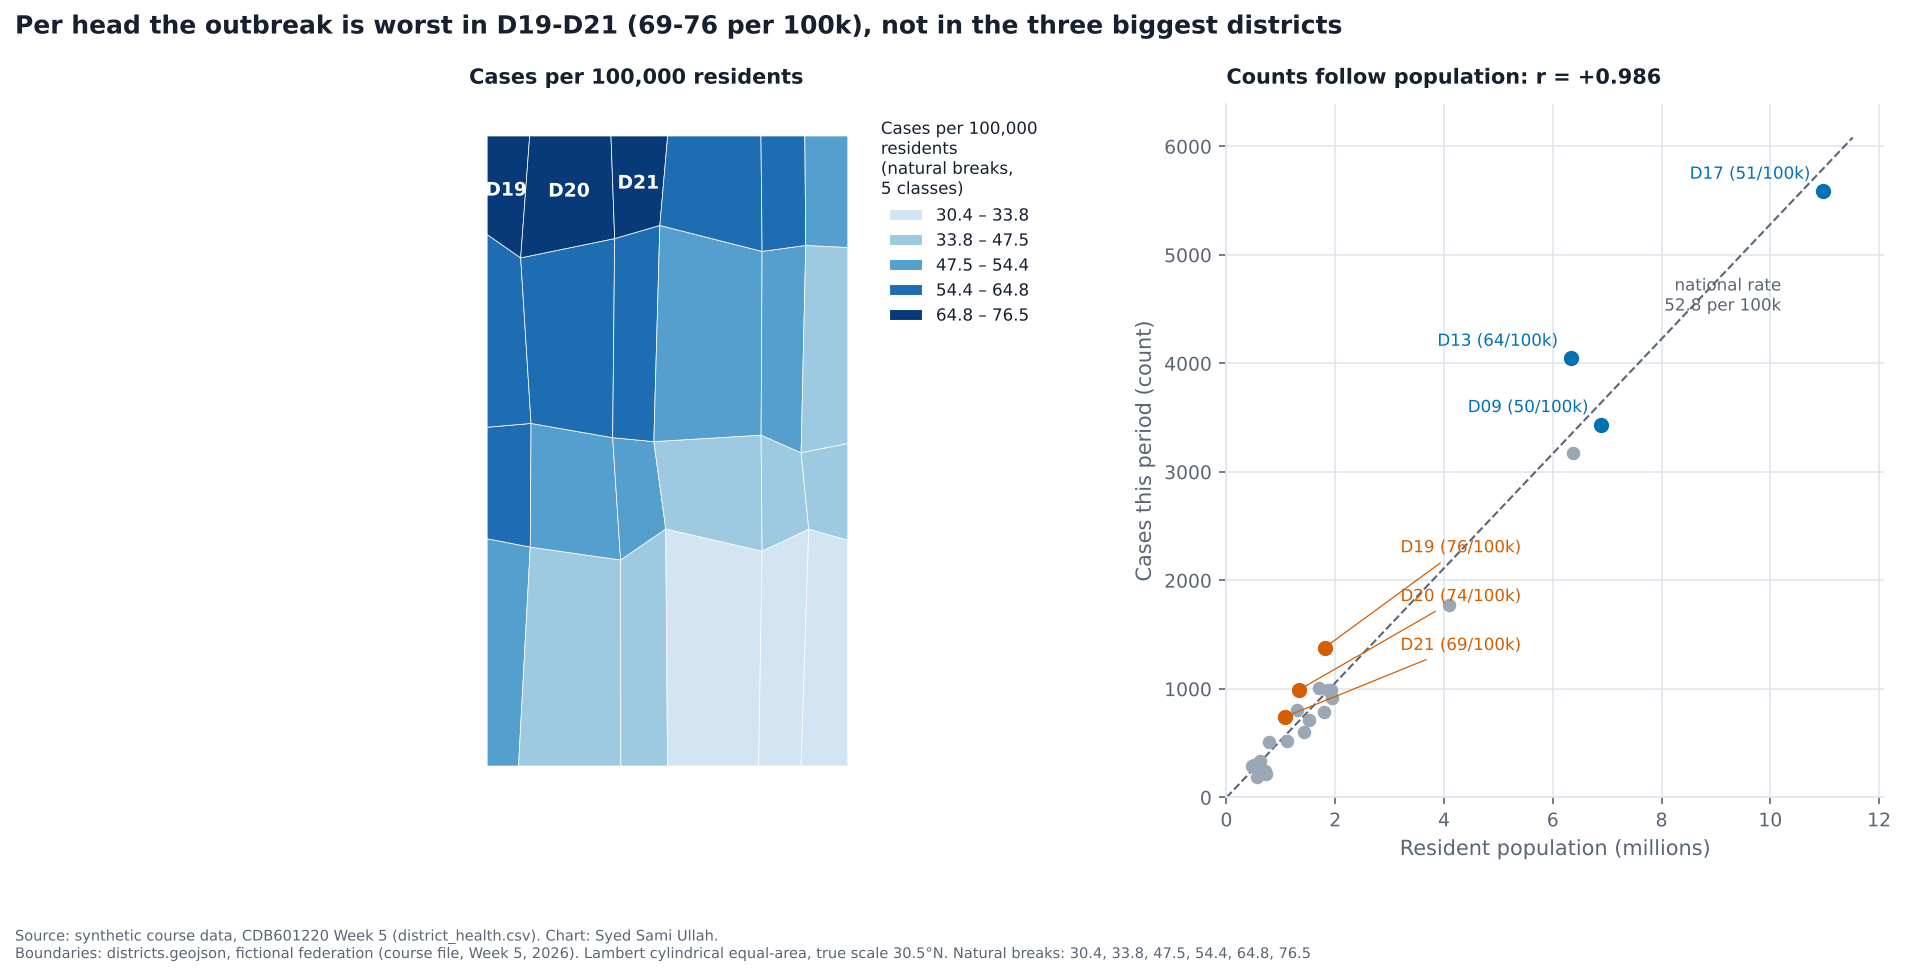

In [7]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.25, 1]})
e_rate = gl.choropleth(ax, FEATS, dict(zip(dh.code, dh.rate)), "natural", 5,
                       legend_title="Cases per 100,000\nresidents\n(natural breaks,\n5 classes)", fmt="{:.1f}")
for c in top_rate:
    ax.annotate(c, xy[c], ha="center", va="center", fontsize=9, color="white", fontweight="bold")
ax.set_title("Cases per 100,000 residents", fontsize=10)
pop_m = dh.population / 1e6
ax2.scatter(pop_m, dh.cases, s=30, color=GREY, zorder=3)
xx = np.linspace(0, pop_m.max() * 1.05, 50)
ax2.plot(xx, pooled / 1e5 * xx * 1e6, color=SOFT, lw=1, ls="--")
ax2.text(10.2, pooled / 1e5 * 10.2e6 - 900, f"national rate\n{pooled:.1f} per 100k", color=SOFT, fontsize=8, ha="right")
for c in top_count:
    rr = dh.set_index("code").loc[c]
    ax2.annotate(f"{c} ({rr.rate:.0f}/100k)", (rr.population / 1e6, rr.cases), xytext=(-6, 6),
                 textcoords="offset points", ha="right", fontsize=8, color=BLUE)
    ax2.scatter(rr.population / 1e6, rr.cases, s=40, color=BLUE, zorder=4)
for c in top_rate:
    rr = dh.set_index("code").loc[c]
    ax2.scatter(rr.population / 1e6, rr.cases, s=40, color=ORANGE, zorder=4)
    ax2.annotate(f"{c} ({rr.rate:.0f}/100k)", (rr.population / 1e6, rr.cases),
                 xytext=(3.2, {"D19": 2300, "D20": 1850, "D21": 1400}[c]), textcoords="data", fontsize=8,
                 color=ORANGE, va="center", arrowprops=dict(arrowstyle="-", color=ORANGE, lw=0.6))
ax2.set_xlim(0, None)
ax2.set_ylim(0, None)
ax2.set_xlabel("Resident population (millions)")
ax2.set_ylabel("Cases this period (count)")
ax2.set_title(f"Counts follow population: r = +{r_cp:.3f}", fontsize=10)
fig.suptitle("Per head the outbreak is worst in D19-D21 (69-76 per 100k), not in the three biggest districts",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save(fig, "partA_case02_redesign.png", "district_health.csv", BOUNDS + " Natural breaks: " + ", ".join(f"{e:.1f}" for e in e_rate))

**What the redesign shows.** Per resident, the dark districts move to the north-west (D19-D21). The right panel shows why the count map misled: the counts sit on the national-rate line and the big districts are simply at the far end of it.

---
## Case 3 · "GDP per capita barely varies across the sample"
Recipe: min-max scale the five numeric columns to 0-1, parallel coordinates, look at the `gdp_pc` axis.

min-max gdp_pc: 58 of 60 below 0.10, median 0.017


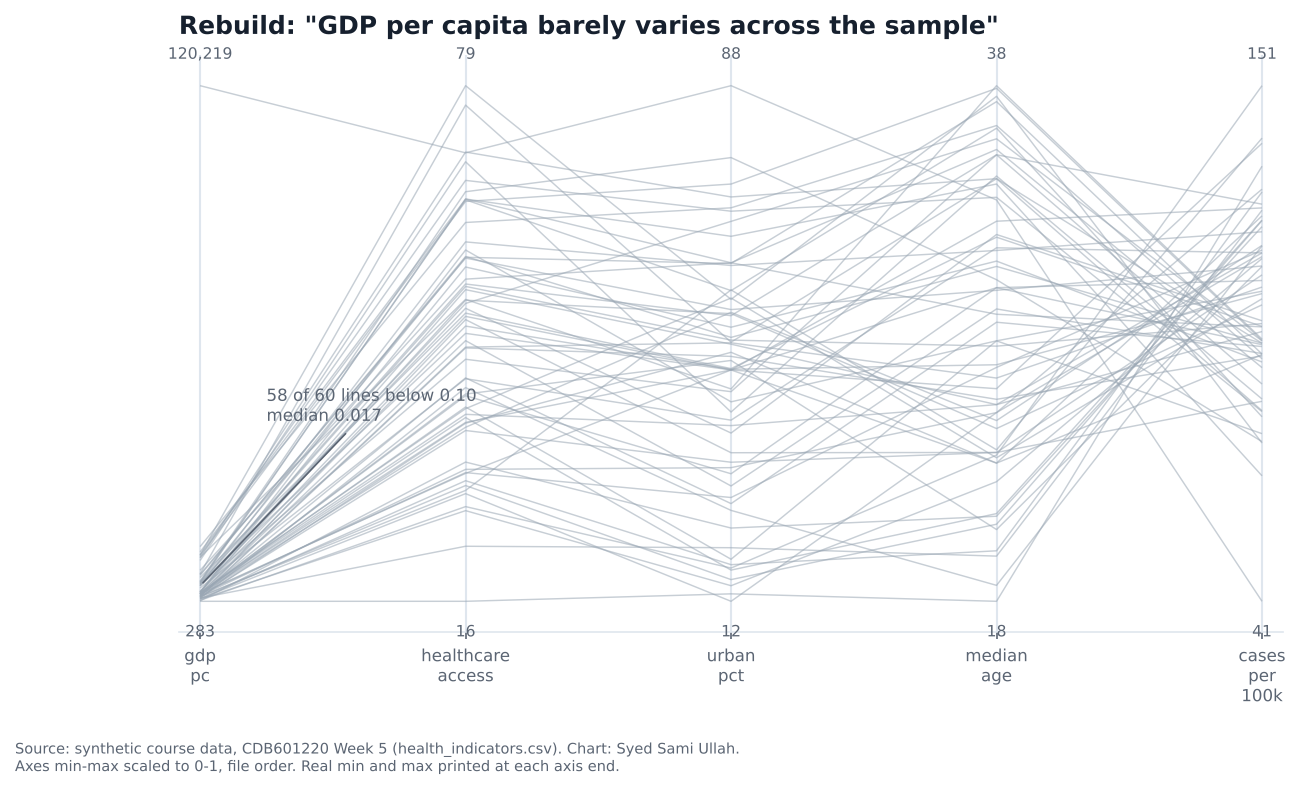

In [8]:
mm = gl.scale_frame(hi, NUM, "minmax")
n_low = int((mm.gdp_pc < 0.10).sum())
assert n_low == 58 and round(mm.gdp_pc.median(), 3) == 0.017
print(f"min-max gdp_pc: {n_low} of 60 below 0.10, median {mm.gdp_pc.median():.3f}")

fig, ax = plt.subplots(figsize=(9.5, 5))
gl.pcp(ax, hi, NUM, "minmax")
ax.set_title('Rebuild: "GDP per capita barely varies across the sample"')
ax.annotate(f"{n_low} of 60 lines below 0.10\nmedian 0.017", (0, 0.03), xytext=(0.25, 0.35), fontsize=8, color=SOFT,
            arrowprops=dict(arrowstyle="-", color=SOFT, lw=0.8))
save(fig, "partA_case03_rebuild.png", "health_indicators.csv", "Axes min-max scaled to 0-1, file order. Real min and max printed at each axis end.")

**What this chart shows.** Every line leaves the GDP axis from almost the same spot at the bottom, except one line that starts at the very top. Read literally, GDP is the one variable that doesn't vary.

In [9]:
g = hi.sort_values("gdp_pc", ascending=False)
print(g.head(3)[["country", "region", "gdp_pc", "healthcare_access", "urban_pct", "median_age", "pop_m"]].to_string(index=False))
print(f"largest / second largest: {g.gdp_pc.iloc[0] / g.gdp_pc.iloc[1]:.1f}x")
spread = pd.DataFrame({"max/min": hi[NUM].max() / hi[NUM].min(), "CV (sd/mean)": hi[NUM].std() / hi[NUM].mean()}).round(2)
print(spread.to_string())
rest = hi[hi.country != "Aldonia"]
mm_rest = gl.scale_frame(rest, NUM, "minmax").gdp_pc
print(f"without Aldonia: gdp {rest.gdp_pc.min():,} to {rest.gdp_pc.max():,} ({rest.gdp_pc.max() / rest.gdp_pc.min():.0f}x), "
      f"min-max median {mm_rest.median():.3f}, below 0.10: {(mm_rest < 0.10).sum()} of 59")
hi_log = hi.assign(gdp_pc=np.log10(hi.gdp_pc))
mm_log = gl.scale_frame(hi_log, NUM, "minmax").gdp_pc
print(f"log10 then min-max: median {mm_log.median():.3f}, below 0.10: {(mm_log < 0.10).sum()} of 60, IQR {mm_log.quantile(.25):.2f}-{mm_log.quantile(.75):.2f}")

   country   region  gdp_pc  healthcare_access  urban_pct  median_age  pop_m
   Aldonia   Andara  120219               71.0       88.0        33.4    1.9
Brightmoor  Dravira   13009               62.4       70.0        36.2   20.1
  Durnhill Borealis   11758               65.3       61.9        35.3   27.1
largest / second largest: 9.2x
                   max/min  CV (sd/mean)
gdp_pc              424.80          2.65
healthcare_access     5.08          0.30
urban_pct             7.33          0.40
median_age            2.06          0.19
cases_per_100k        3.69          0.19
without Aldonia: gdp 283 to 13,009 (46x), min-max median 0.162, below 0.10: 16 of 59
log10 then min-max: median 0.351, below 0.10: 3 of 60, IQR 0.28-0.47


- **Conclusion it invites:** GDP per head is about the same in every country, so it can't explain anything else in the plot.
- **Decoy:** my first thought was that Aldonia's $120,219 is a typo with an extra digit, so just delete it. Ruled out: the rest of its row fits a small rich state (88% urban, access 71, median age 33.4, 1.9 M people), and the data dictionary calls it "a real kind of country". Deleting it also doesn't fix the axis: min-max on the other 59 still puts the median at 0.16 with 16 of 59 lines under 0.10, because the next richest country is 46× the poorest.
- **Mechanism:** **min-max scaling** lets one value set the range. Aldonia is 9.2× the second richest, so the other 59 countries are squeezed into the bottom tenth of the axis (58 of 60 below 0.10, median 0.017). GDP actually varies the *most* of the five columns: 425× from poorest to richest and a coefficient of variation of 2.65, against 0.19-0.40 for the others.

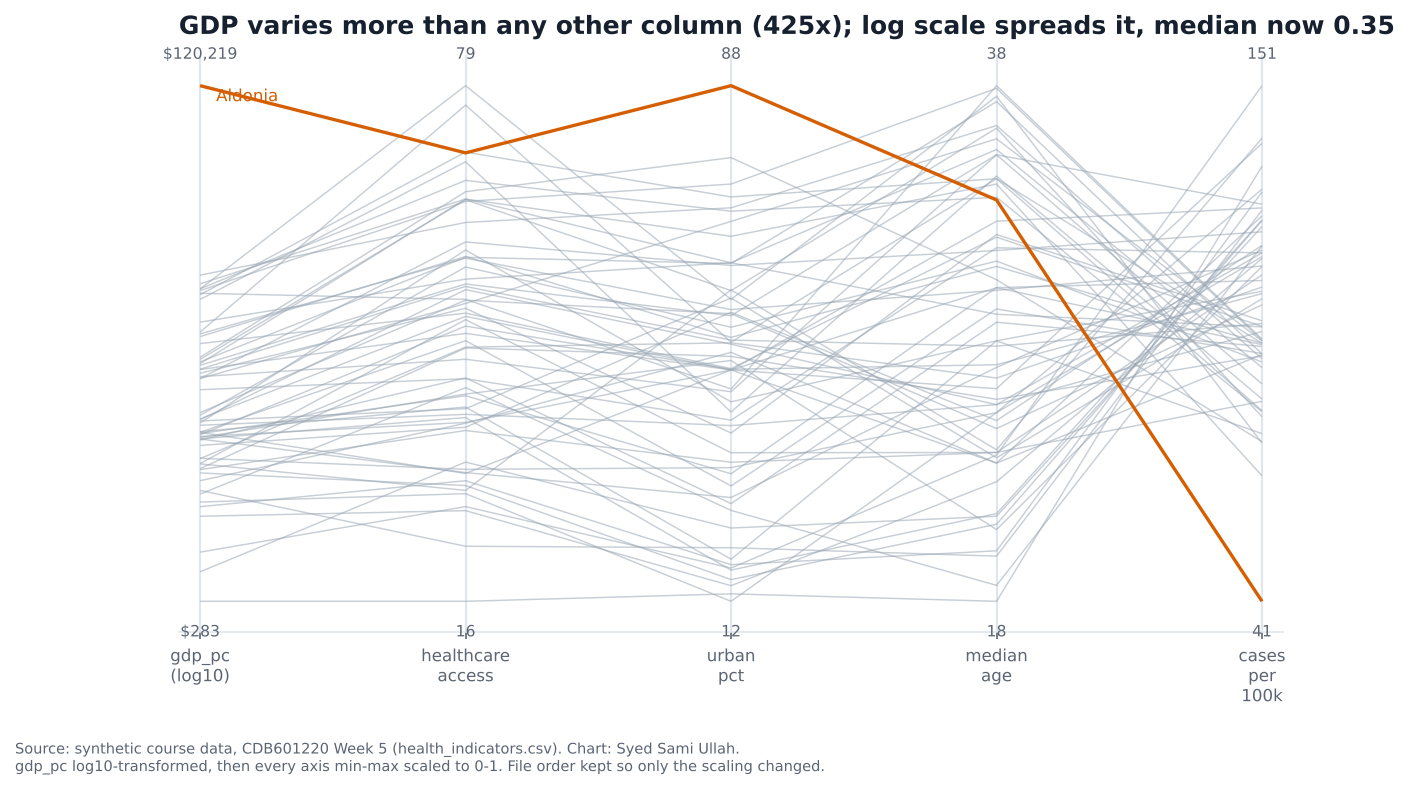

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 5))
gl.pcp(ax, hi_log, NUM, "minmax", highlight=(hi.country == "Aldonia").to_numpy())
for t in list(ax.texts):                     # pcp printed log10 ends; put real dollars back
    t.remove()
for x, c in enumerate(NUM):
    lo_, hi_ = (hi[c].min(), hi[c].max())
    f = "${:,.0f}" if c == "gdp_pc" else "{:,.0f}"
    ax.annotate(f.format(lo_), (x, -0.045), ha="center", va="top", fontsize=7.5, color=SOFT)
    ax.annotate(f.format(hi_), (x, 1.045), ha="center", va="bottom", fontsize=7.5, color=SOFT)
ax.set_xticklabels(["gdp_pc\n(log10)"] + [c.replace("_", "\n") for c in NUM[1:]], fontsize=8)
ax.text(0.06, 0.97, "Aldonia", color=ORANGE, fontsize=8)
ax.set_title(f"GDP varies more than any other column (425x); log scale spreads it, median now {mm_log.median():.2f}")
save(fig, "partA_case03_redesign.png", "health_indicators.csv",
     "gdp_pc log10-transformed, then every axis min-max scaled to 0-1. File order kept so only the scaling changed.")

**What the redesign shows.** Same plot, same order, one decision changed: GDP goes through log10 before min-max. The GDP axis now spreads from bottom to top, Aldonia is still there (orange) but no longer sets the scale, and you can see GDP lines running roughly parallel to healthcare access.

---
## Case 4 · "Healthcare access and case rate are unrelated - there is no crossing pattern between them"
Recipe: parallel coordinates in file column order, min-max scaled, read the gaps between adjacent axes.

healthcare_access and cases_per_100k are 3 axes apart, with ['urban_pct', 'median_age'] between them


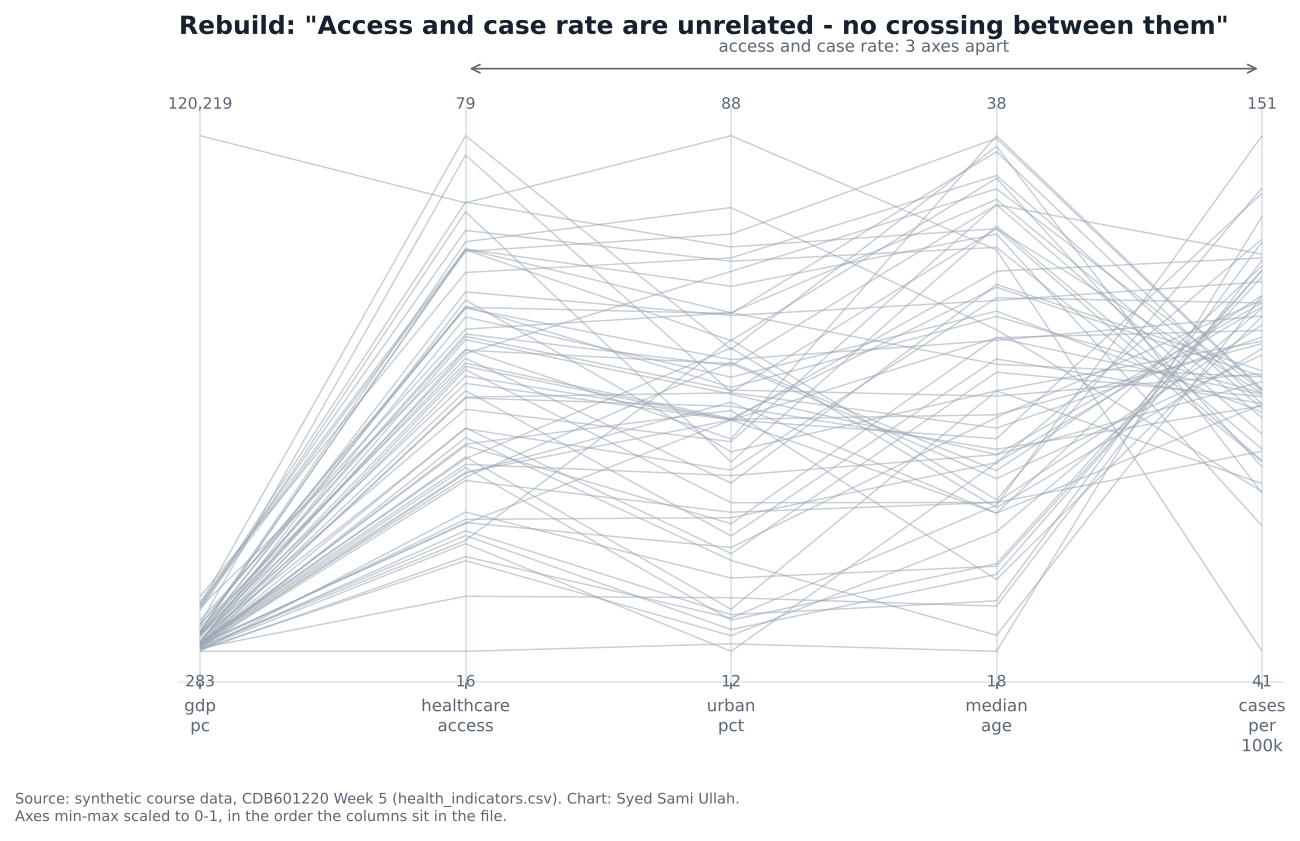

In [11]:
pos = {c: i for i, c in enumerate(NUM)}
gap = abs(pos["healthcare_access"] - pos["cases_per_100k"])
between = NUM[pos["healthcare_access"] + 1: pos["cases_per_100k"]]
assert gap == 3 and between == ["urban_pct", "median_age"]
print(f"healthcare_access and cases_per_100k are {gap} axes apart, with {between} between them")

fig, ax = plt.subplots(figsize=(9.5, 5))
gl.pcp(ax, hi, NUM, "minmax")
ax.annotate("", xy=(4, 1.13), xytext=(1, 1.13), xycoords="data",
            arrowprops=dict(arrowstyle="<->", color=SOFT, lw=0.8), annotation_clip=False)
ax.text(2.5, 1.155, "access and case rate: 3 axes apart", ha="center", va="bottom", fontsize=8, color=SOFT)
ax.set_title('Rebuild: "Access and case rate are unrelated - no crossing between them"', pad=34)
save(fig, "partA_case04_rebuild.png", "health_indicators.csv", "Axes min-max scaled to 0-1, in the order the columns sit in the file.")

**What this chart shows.** Lines mostly run in parallel between the first four axes, and the only big crossing band is between `median_age` and `cases_per_100k`. Nothing is visible between access and case rate because they never sit next to each other.

In [12]:
r_ac = hi.healthcare_access.corr(hi.cases_per_100k)
rho_ac = stats.spearmanr(hi.healthcare_access, hi.cases_per_100k)[0]
chain = corr_chain(hi, NUM)
print(f"r(access, cases) = {r_ac:+.3f}, Spearman {rho_ac:+.3f}")
print("greedy chain:", " -> ".join(chain))
print("|r| of every pair:\n", hi[NUM].corr().abs().round(2).to_string())
for name, order in [("file order", NUM), ("greedy chain", chain)]:
    print(f"\n{name}: crossings between adjacent axes (of 1,770 line pairs)")
    for a, b in zip(order, order[1:]):
        print(f"  {a:>18s} | {b:<18s} r = {hi[a].corr(hi[b]):+.2f}  crossings = {crossings(mm[a], mm[b]):,}")
assert chain == ["healthcare_access", "cases_per_100k", "urban_pct", "median_age", "gdp_pc"]
assert round(r_ac, 3) == -0.799

r(access, cases) = -0.799, Spearman -0.810
greedy chain: healthcare_access -> cases_per_100k -> urban_pct -> median_age -> gdp_pc
|r| of every pair:
                    gdp_pc  healthcare_access  urban_pct  median_age  cases_per_100k
gdp_pc               1.00               0.36       0.44        0.28            0.52
healthcare_access    0.36               1.00       0.75        0.80            0.80
urban_pct            0.44               0.75       1.00        0.64            0.62
median_age           0.28               0.80       0.64        1.00            0.59
cases_per_100k       0.52               0.80       0.62        0.59            1.00

file order: crossings between adjacent axes (of 1,770 line pairs)
              gdp_pc | healthcare_access  r = +0.36  crossings = 268
   healthcare_access | urban_pct          r = +0.75  crossings = 368
           urban_pct | median_age         r = +0.64  crossings = 499
          median_age | cases_per_100k     r = -0.59  crossings = 1,250



- **Conclusion it invites:** access and case rate don't move together, so improving access wouldn't change the case rate.
- **Decoy:** my first thought was that the link is there but non-linear or driven by one country, so a plot of lines wouldn't show it anyway. Ruled out: Pearson r = −0.799 and Spearman −0.810, so it's monotonic and no single outlier makes it. It's the strongest pair in the whole table.
- **Mechanism:** a parallel coordinates plot only shows the relationship between **adjacent** axes, so the **axis order** decides which pairs you can see. In file order access and case rate are three axes apart. Put next to each other they produce 1,435 crossings out of 1,770 line pairs (the X-shaped waist). The file order spends its four adjacent slots on pairs with |r| = 0.36, 0.75, 0.64 and 0.59 and leaves the strongest pair in the table (0.80) out.

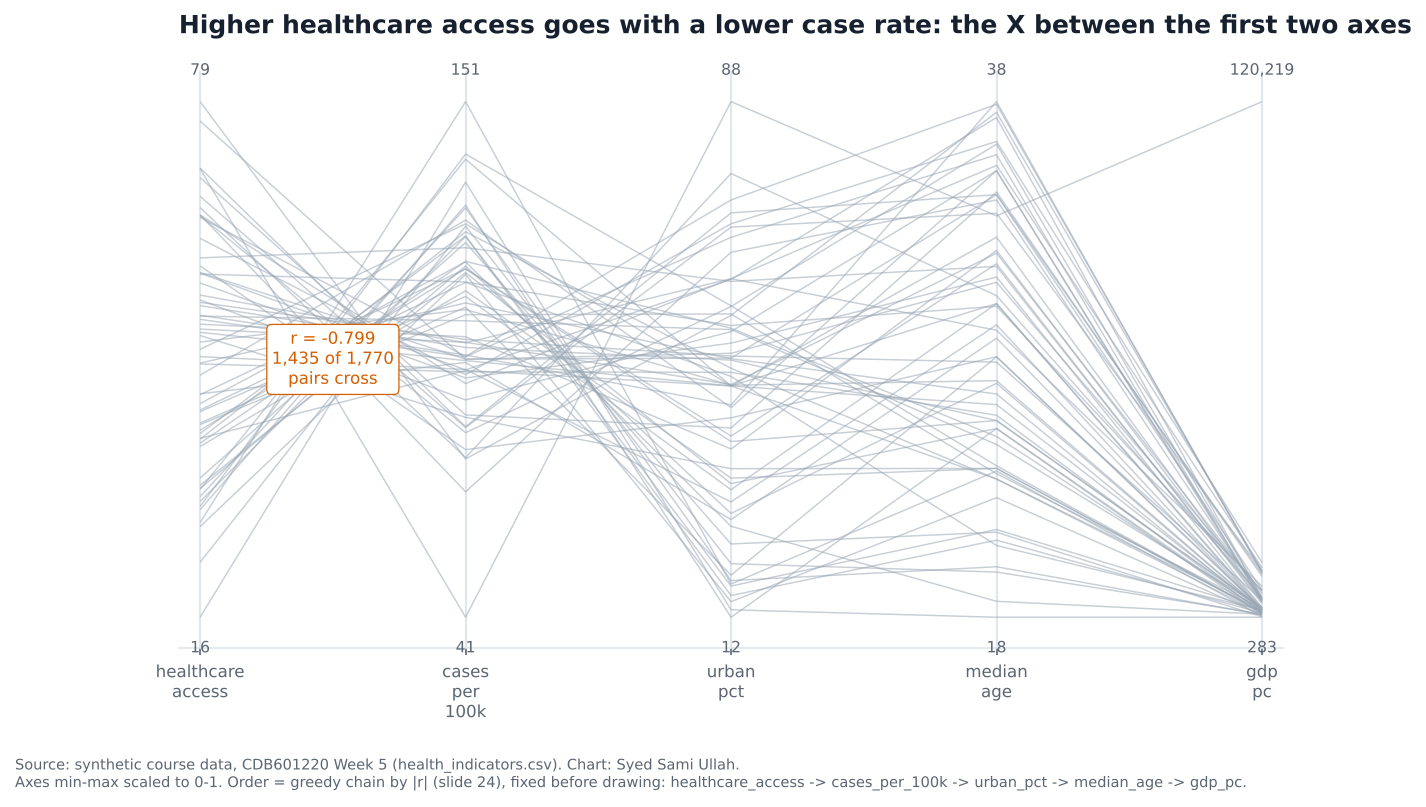

In [13]:
fig, ax = plt.subplots(figsize=(9.5, 5))
gl.pcp(ax, hi, chain, "minmax")
ax.text(0.5, 0.5, f"r = {r_ac:+.3f}\n{crossings(mm[chain[0]], mm[chain[1]]):,} of 1,770\npairs cross", ha="center", va="center",
        fontsize=8, color=ORANGE, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=ORANGE, lw=0.6), zorder=5)
ax.set_title("Higher healthcare access goes with a lower case rate: the X between the first two axes", pad=18)
save(fig, "partA_case04_redesign.png", "health_indicators.csv",
     "Axes min-max scaled to 0-1. Order = greedy chain by |r| (slide 24), fixed before drawing: " + " -> ".join(chain) + ".")

**What the redesign shows.** Same lines and same scaling, only the order changed. With access and case rate side by side, the lines cross in a tight X, high access to low cases. (GDP is still flat on the far right; that's the case 3 problem, which I left alone here so the order is the only thing that changed.)

---
## Case 5 · "There is a clear five-level gradient in incidence across the federation"
Recipe: `cases / population * 1e5`, five quantile classes, five-step sequential ramp.

join on code: 24 matched, 0 table rows with no polygon, 0 polygons with no row
rate 31.07 to 33.40 per 100k, spread 7.2% of the mean


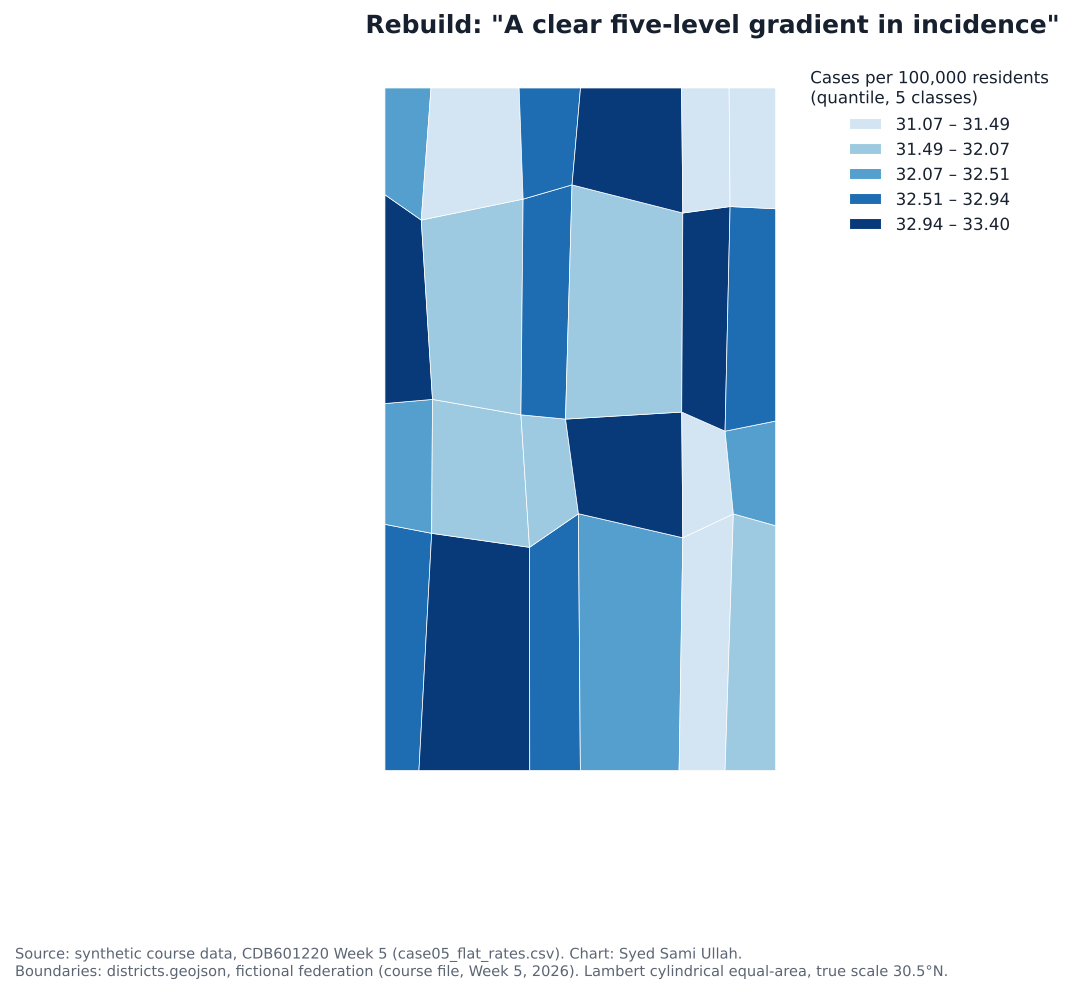

quantile breaks: [31.07, 31.49, 32.07, 32.51, 32.94, 33.4]


In [14]:
c5 = pd.read_csv(DATA / "case05_flat_rates.csv")
c5["rate"] = c5.cases / c5.population * 1e5
spread5 = (c5.rate.max() - c5.rate.min()) / c5.rate.mean() * 100
check_join(FEATS, c5)
assert len(c5) == 24 and round(c5.rate.min(), 2) == 31.07 and round(c5.rate.max(), 2) == 33.40
assert round(spread5, 1) == 7.2
print(f"rate {c5.rate.min():.2f} to {c5.rate.max():.2f} per 100k, spread {spread5:.1f}% of the mean")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
e5 = gl.choropleth(ax, FEATS, dict(zip(c5.code, c5.rate)), "quantile", 5,
                   legend_title="Cases per 100,000 residents\n(quantile, 5 classes)", fmt="{:.2f}")
ax.set_title('Rebuild: "A clear five-level gradient in incidence"')
save(fig, "partA_case05_rebuild.png", "case05_flat_rates.csv", BOUNDS)
print("quantile breaks:", [round(float(e), 2) for e in e5])

**What this chart shows.** A confident five-shade map with dark and pale districts scattered across the federation. The legend gives it away: the whole scale runs from 31.07 to 33.40.

In [15]:
pool5 = c5.cases.sum() / c5.population.sum()
exp5 = pool5 * c5.population
chi2 = float(((c5.cases - exp5) ** 2 / exp5).sum())
p_chi = 1 - stats.chi2.cdf(chi2, len(c5) - 1)
band = 1.96 * np.sqrt(exp5) / c5.population * 1e5
outside5 = int((abs(c5.rate - pool5 * 1e5) > band).sum())
print(f"national pooled rate {pool5 * 1e5:.2f} per 100k")
for sch in ["quantile", "equal", "natural"]:
    e = gl.breaks(c5.rate, sch, 5)
    print(f"{sch:>9s}: breaks {np.round(e, 2).tolist()}  GVF {gl.gvf(c5.rate, e):.3f}  "
          f"counts {np.bincount(gl.class_of(c5.rate, e), minlength=5).tolist()}")
print(f"step between quantile class edges: {np.diff(e5).mean():.2f} per 100k ({np.diff(e5).mean() / c5.rate.mean():.1%} of the mean)")
print(f"Poisson noise alone: 95% band at the median population = +/-{band.median():.2f} per 100k "
      f"(total observed spread {c5.rate.max() - c5.rate.min():.2f})")
print(f"chi-square vs one shared rate: {chi2:.2f} on {len(c5) - 1} df, p = {p_chi:.4f}; districts outside their 95% band: {outside5} of 24")

national pooled rate 32.25 per 100k
 quantile: breaks [31.07, 31.49, 32.07, 32.51, 32.94, 33.4]  GVF 0.959  counts [5, 5, 4, 5, 5]
    equal: breaks [31.07, 31.54, 32.0, 32.47, 32.93, 33.4]  GVF 0.961  counts [6, 3, 5, 5, 5]
  natural: breaks [31.07, 31.51, 32.04, 32.55, 33.02, 33.4]  GVF 0.968  counts [6, 4, 5, 6, 3]
step between quantile class edges: 0.47 per 100k (1.4% of the mean)
Poisson noise alone: 95% band at the median population = +/-4.38 per 100k (total observed spread 2.33)
chi-square vs one shared rate: 2.30 on 23 df, p = 1.0000; districts outside their 95% band: 0 of 24


- **Conclusion it invites:** incidence varies in five clear steps across the federation, so some districts need more attention than others.
- **Decoy:** my first thought was that quantile is just the wrong scheme and Jenks would fix it. Ruled out: natural breaks and equal interval paint the same five-level map, with GVF 0.968 and 0.961 against quantile's 0.959. Any five-class scheme will fill five classes. The scheme isn't the problem.
- **Mechanism:** the **classification** turns a 2.3-point spread into five colours. The rates run 31.07-33.40 (7.2% of the mean), so each quantile class is about 0.47 per 100,000 wide, around 1.4%. Poisson noise alone would move a district of median size by ±4.4 per 100,000 at 95%, almost twice the whole observed spread. 0 of 24 districts fall outside their band, and a chi-square test against one shared rate gives 2.30 on 23 df (p = 1.00). The districts are *more* alike than chance would make them. There is no gradient to classify.

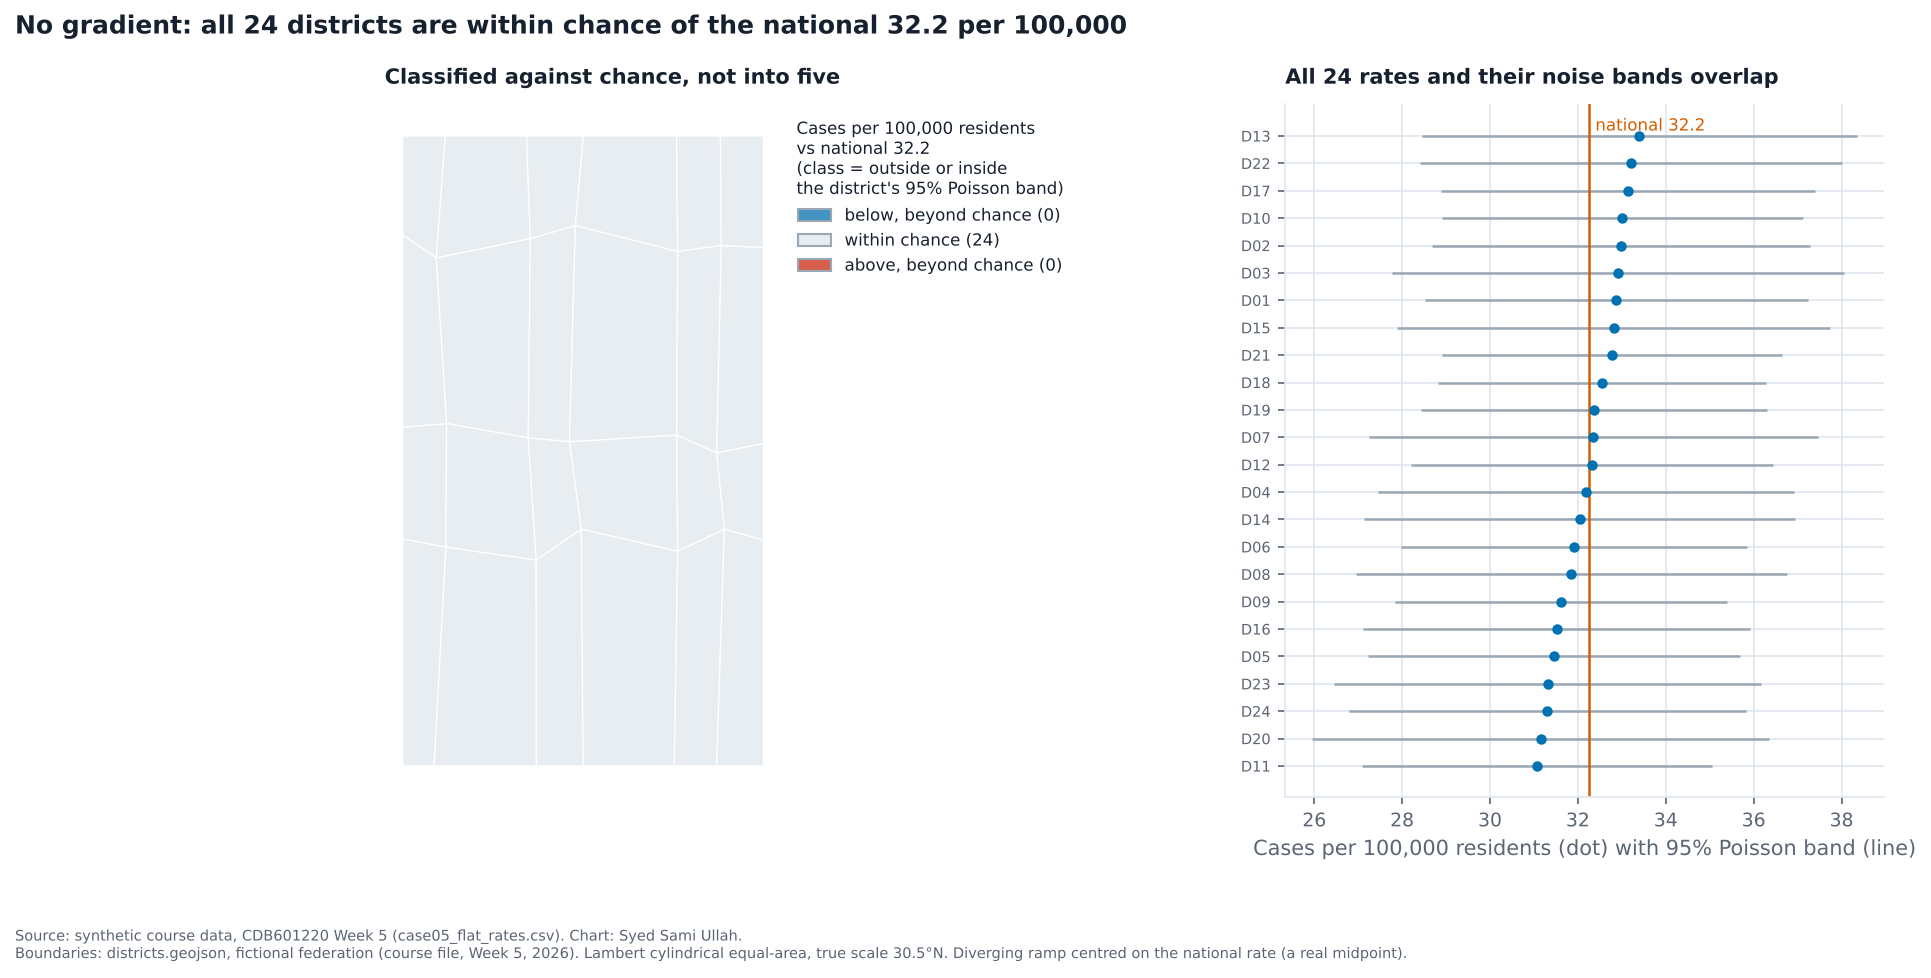

In [16]:
dev = (c5.rate - pool5 * 1e5) / band                    # deviation in units of each district's 95% band
cls = np.select([dev < -1, dev > 1], [0, 2], 1)
labels3 = ["below, beyond chance", "within chance", "above, beyond chance"]
cmap = plt.get_cmap(PALETTE["diverging"])
cols3 = [cmap(0.2), "#E8EDF2", cmap(0.8)]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.2, 1.1]})
cls_of = dict(zip(c5.code, cls))
gl.outlines(ax, FEATS, color="white", lw=0.6, facecolor=[cols3[cls_of[f["code"]]] for f in FEATS])
ax.legend(handles=[Patch(facecolor=cols3[k], edgecolor=GREY, label=f"{labels3[k]} ({(cls == k).sum()})") for k in range(3)],
          title=f"Cases per 100,000 residents\nvs national {pool5 * 1e5:.1f}\n(class = outside or inside\nthe district's 95% Poisson band)",
          loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, title_fontsize=8, frameon=False)
ax.set_title("Classified against chance, not into five", fontsize=10)
srt = c5.sort_values("rate").reset_index(drop=True)
bnd = 1.96 * np.sqrt(pool5 * srt.population) / srt.population * 1e5
ax2.errorbar(srt.rate, range(24), xerr=bnd, fmt="o", color=BLUE, ecolor=GREY, elinewidth=1.2, capsize=0, ms=4)
ax2.axvline(pool5 * 1e5, color=ORANGE, lw=1.2)
ax2.text(pool5 * 1e5 + 0.15, 23.2, f"national {pool5 * 1e5:.1f}", color=ORANGE, fontsize=8)
ax2.set_yticks(range(24))
ax2.set_yticklabels(srt.code, fontsize=7)
ax2.set_xlabel("Cases per 100,000 residents (dot) with 95% Poisson band (line)")
ax2.set_title("All 24 rates and their noise bands overlap", fontsize=10)
fig.subplots_adjust(wspace=0.6)
fig.suptitle(f"No gradient: all 24 districts are within chance of the national {pool5 * 1e5:.1f} per 100,000",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save(fig, "partA_case05_redesign.png", "case05_flat_rates.csv", BOUNDS + " Diverging ramp centred on the national rate (a real midpoint).")
assert (cls == 1).all()

**What the redesign shows.** Classified against chance instead of into five equal bins, every district lands in the same class and the map is one flat colour. That's the honest picture. The strip on the right shows why: every district's noise band crosses the national line.

---
## Case 6 · "Unit U32 is a hotspot - it is running at nearly five times the national rate"
Recipe: `cases / population * 1e5` per unit, rank them, bar-chart, compare the worst unit to the pooled national rate.

pooled 8.72; U32 40.9 = 4.7x from 9 cases in 22,000
units over 100k: 10, rates 5.5 to 12.0


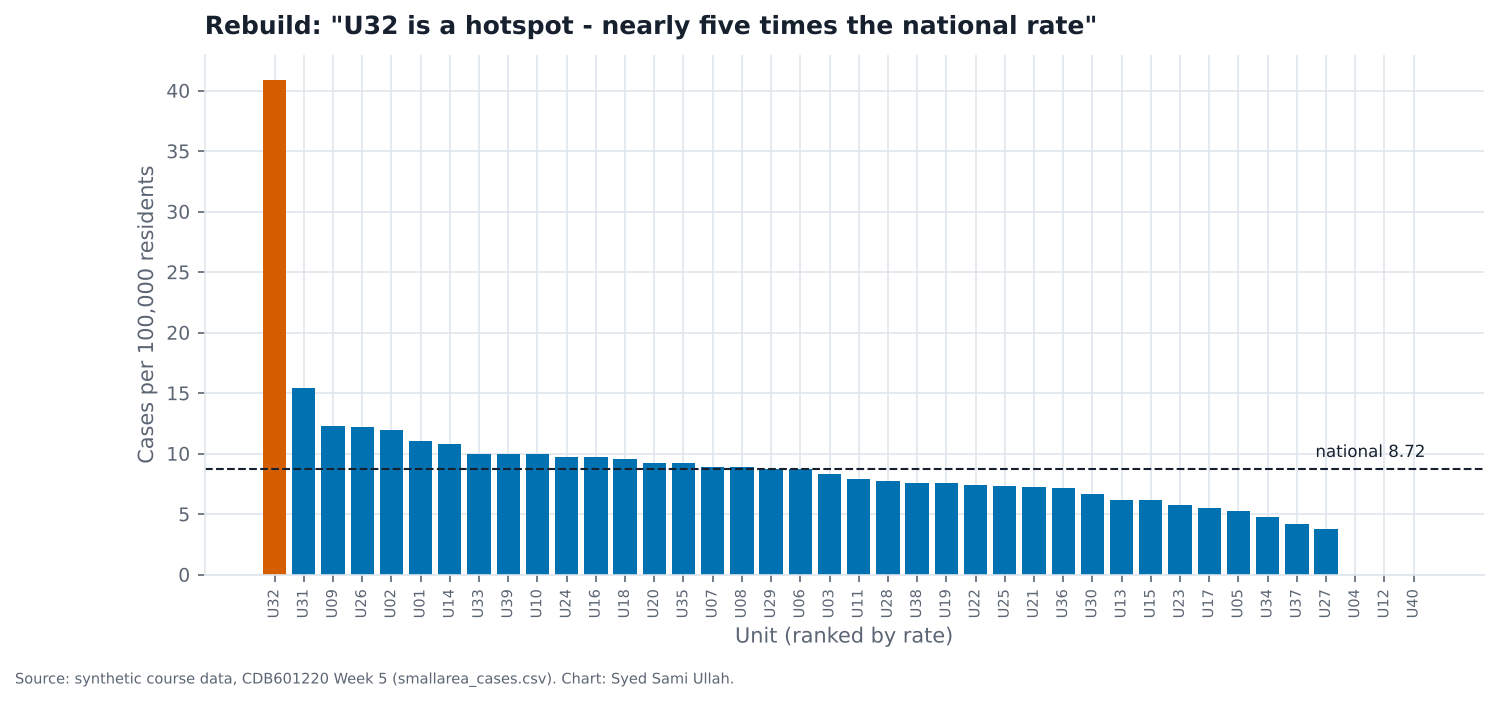

In [17]:
s6 = pd.read_csv(DATA / "smallarea_cases.csv")
s6["rate"] = s6.cases / s6.population * 1e5
pool6 = s6.cases.sum() / s6.population.sum() * 1e5
u32 = s6.set_index("unit").loc["U32"]
big6 = s6[s6.population > 100_000]
assert len(s6) == 40 and round(pool6, 2) == 8.72
assert round(u32.rate, 1) == 40.9 and round(u32.rate / pool6, 1) == 4.7 and u32.cases == 9 and u32.population == 22_000
assert len(big6) == 10 and round(big6.rate.min(), 1) == 5.5 and round(big6.rate.max(), 1) == 12.0
print(f"pooled {pool6:.2f}; U32 {u32.rate:.1f} = {u32.rate / pool6:.1f}x from {u32.cases:.0f} cases in {u32.population:,.0f}")
print(f"units over 100k: {len(big6)}, rates {big6.rate.min():.1f} to {big6.rate.max():.1f}")

srt6 = s6.sort_values("rate", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(srt6.unit, srt6.rate, color=[ORANGE if u == "U32" else BLUE for u in srt6.unit])
ax.axhline(pool6, color=INK, lw=1, ls="--")
ax.text(39.4, pool6 + 1, f"national {pool6:.2f}", ha="right", fontsize=8, color=INK)
ax.set_xticks(range(40))
ax.set_xticklabels(srt6.unit, rotation=90, fontsize=7)
ax.set_ylabel("Cases per 100,000 residents")
ax.set_xlabel("Unit (ranked by rate)")
ax.set_title('Rebuild: "U32 is a hotspot - nearly five times the national rate"')
save(fig, "partA_case06_rebuild.png", "smallarea_cases.csv")

**What this chart shows.** One orange bar towering over the rest at 40.9, almost five times the dashed national line. Nothing on the chart says how many people are behind each bar.

In [18]:
lam32 = pool6 / 1e5 * u32.population
ci_lo, ci_hi = stats.chi2.ppf(0.025, 2 * u32.cases) / 2, stats.chi2.ppf(0.975, 2 * (u32.cases + 1)) / 2
print(f"U32: expected {lam32:.2f} cases at the national rate; one case moves its rate by {1e5 / u32.population:.1f} per 100k")
print(f"U32 exact 95% interval for its rate: {ci_lo / u32.population * 1e5:.1f} to {ci_hi / u32.population * 1e5:.1f} per 100k")
print(f"P(9 or more | expected {lam32:.2f}) = {1 - stats.poisson.cdf(8, lam32):.5f}; with 40 units looked at: {min(1, 40 * (1 - stats.poisson.cdf(8, lam32))):.3f}")
print(f"unweighted mean of the 40 unit rates: {s6.rate.mean():.2f} -> U32 is {u32.rate / s6.rate.mean():.1f}x that")
print("top 3 and bottom 3 units by rate:")
print(pd.concat([srt6.head(3), srt6.tail(3)])[["unit", "cases", "population", "rate"]].round(1).to_string(index=False))
fl = gl.funnel_limits(s6.population, pool6)
lam = pool6 / 1e5 * s6.population
lo95, hi95 = (lam - 1.96 * np.sqrt(lam)) / s6.population * 1e5, (lam + 1.96 * np.sqrt(lam)) / s6.population * 1e5
out6 = s6[(s6.rate < lo95) | (s6.rate > hi95)]
print(f"outside the 95% funnel: {len(out6)} of 40 ({out6.unit.tolist()}); expected by chance: {0.05 * 40:.0f}")

U32: expected 1.92 cases at the national rate; one case moves its rate by 4.5 per 100k
U32 exact 95% interval for its rate: 18.7 to 77.7 per 100k
P(9 or more | expected 1.92) = 0.00018; with 40 units looked at: 0.007
unweighted mean of the 40 unit rates: 8.58 -> U32 is 4.8x that
top 3 and bottom 3 units by rate:
unit  cases  population  rate
 U32      9       22000  40.9
 U31      4       26000  15.4
 U09      7       57000  12.3
 U04      0        5000   0.0
 U12      0       39000   0.0
 U40      0        5000   0.0
outside the 95% funnel: 1 of 40 (['U32']); expected by chance: 2


- **Conclusion it invites:** something is going on in U32, which is running at 4.7× the national rate and needs an investigation team.
- **Decoy:** my first thought was that the comparison is unfair: the pooled rate is dominated by the big units, so U32 should be compared to the average unit. Ruled out: the plain mean of the 40 unit rates is 8.58, close to the pooled 8.72, so U32 is still 4.8× that. The baseline isn't the issue.
- **Mechanism:** a **small denominator**. U32's rate rests on 9 cases in 22,000 people. At the national rate it would expect 1.9 cases, and every single case moves its rate by 4.5 per 100,000, half the national rate. Its exact 95% interval runs from 18.7 to 77.7. The ranking puts small units at **both** ends: the top two (U32, U31) are under 30,000 people and the bottom three are zeros from units of 5,000-39,000, while the 10 units over 100,000 all sit between 5.5 and 12.0. The file has one true rate everywhere, so the spread is noise that grows as population shrinks. In the funnel, 1 of 40 units is outside the 95% limits, fewer than the 2 you'd expect by chance from 40 units. U32 is unusual (p ≈ 0.007 even after allowing for 40 looks), but it is still nine cases. That's a reason to check the records, not to publish a hotspot.

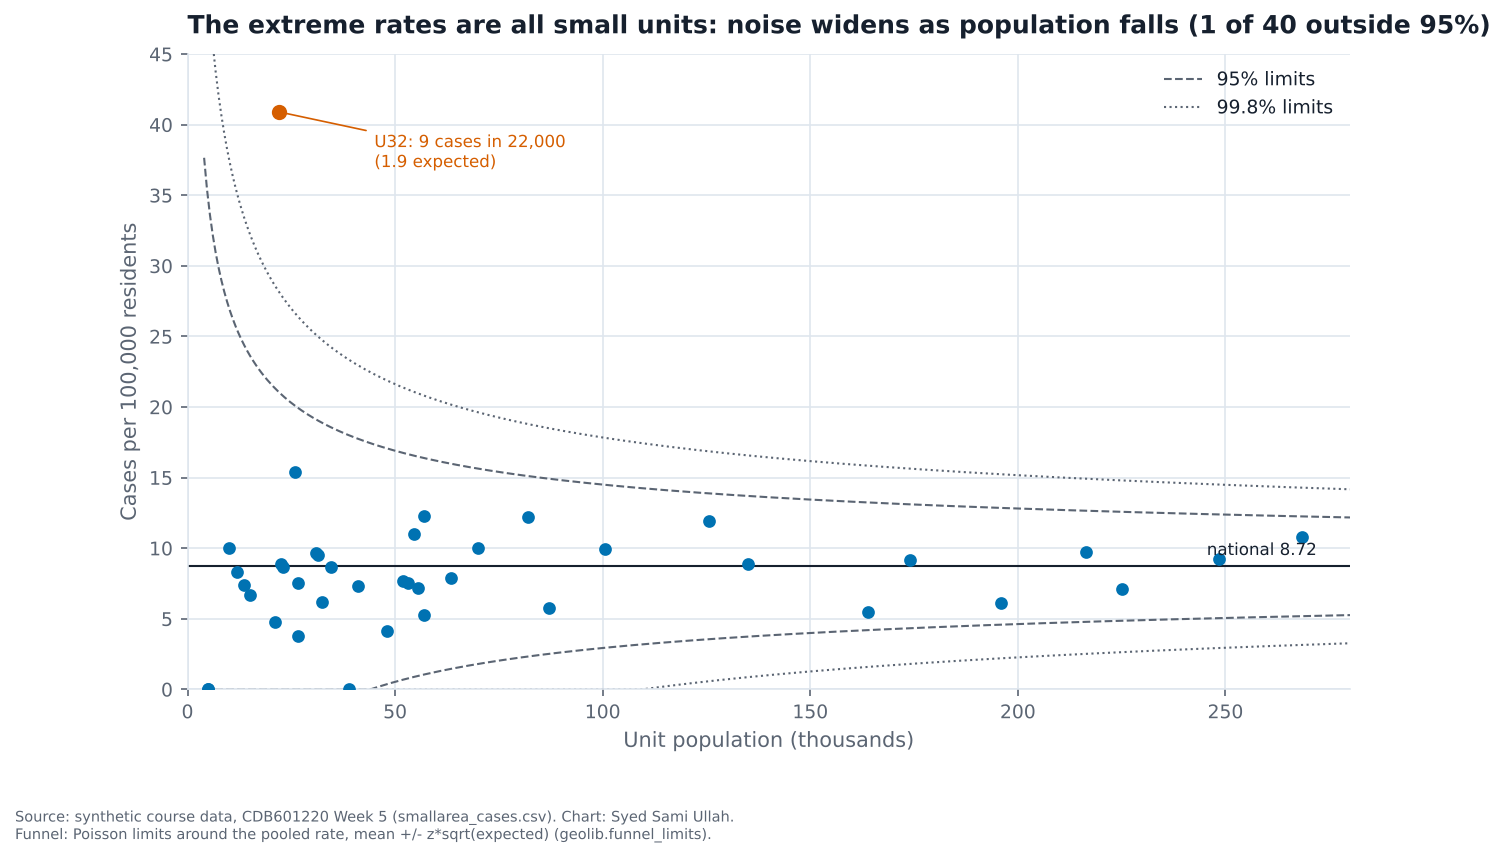

In [19]:
fig, ax = plt.subplots(figsize=(10, 5.5))
pp = np.linspace(4_000, 280_000, 400)
lam_p = pool6 / 1e5 * pp
for z, ls, lab in [(1.96, "--", "95% limits"), (3.09, ":", "99.8% limits")]:
    ax.plot(pp / 1e3, np.maximum(lam_p - z * np.sqrt(lam_p), 0) / pp * 1e5, color=SOFT, ls=ls, lw=1)
    ax.plot(pp / 1e3, (lam_p + z * np.sqrt(lam_p)) / pp * 1e5, color=SOFT, ls=ls, lw=1, label=lab)
ax.axhline(pool6, color=INK, lw=1)
ax.scatter(s6.population / 1e3, s6.rate, s=26, color=BLUE, zorder=3)
ax.scatter(u32.population / 1e3, u32.rate, s=40, color=ORANGE, zorder=4)
ax.annotate(f"U32: 9 cases in 22,000\n(1.9 expected)", (22, u32.rate), xytext=(45, 37), fontsize=8, color=ORANGE,
            arrowprops=dict(arrowstyle="-", color=ORANGE, lw=0.8))
ax.text(272, pool6 + 0.8, f"national {pool6:.2f}", ha="right", fontsize=8, color=INK)
ax.set_xlim(0, 280)
ax.set_ylim(0, 45)
ax.set_xlabel("Unit population (thousands)")
ax.set_ylabel("Cases per 100,000 residents")
ax.legend(loc="upper right")
ax.set_title("The extreme rates are all small units: noise widens as population falls (1 of 40 outside 95%)")
save(fig, "partA_case06_redesign.png", "smallarea_cases.csv", "Funnel: Poisson limits around the pooled rate, mean +/- z*sqrt(expected) (geolib.funnel_limits).")

**What the redesign shows.** Plotted against population, the rates form a funnel: wild at the small end, tight at the big end. U32 is the one unit poking out, at the narrow-denominator end, and the zero-rate units on the floor are just as small.

---
## Case 7 · "District income and case rate are only weakly related - r is about −0.31"
Recipe: correlate `income_pc_usd` with `cases / population * 1e5` across the 24 districts.

r = -0.308 across 24 districts (p = 0.14)


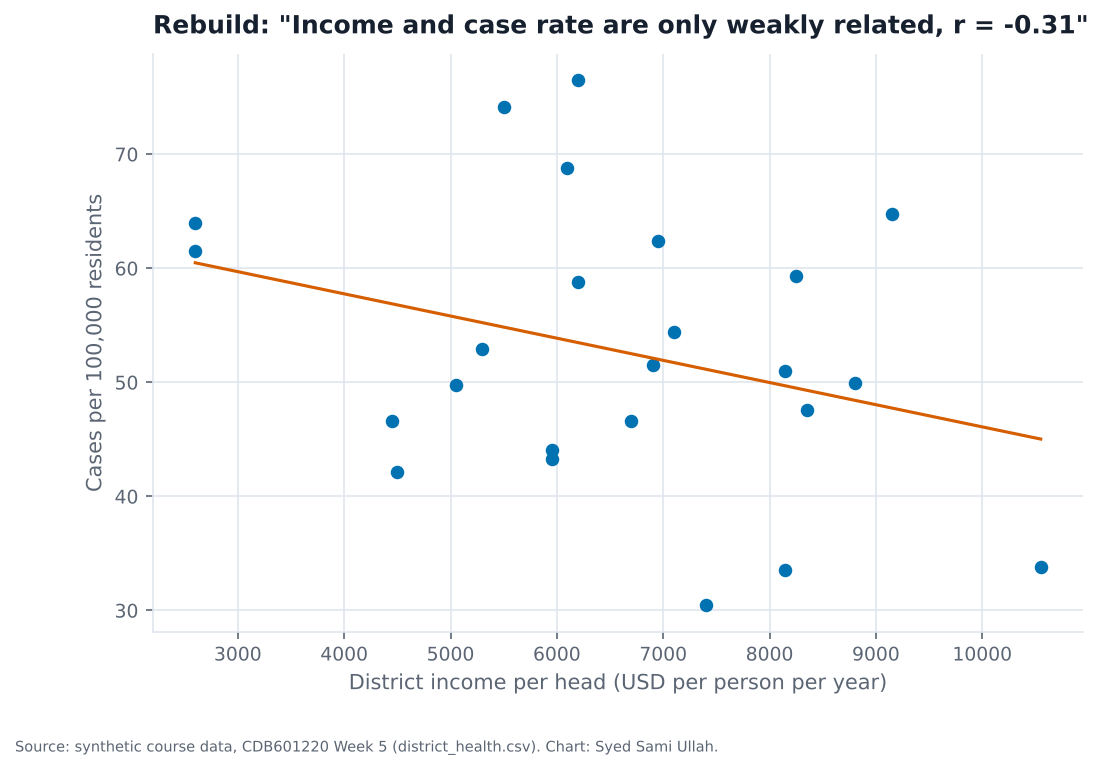

In [20]:
r7, p7 = stats.pearsonr(dh.income_pc_usd, dh.rate)
assert round(r7, 3) == -0.308
print(f"r = {r7:+.3f} across 24 districts (p = {p7:.2f})")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(dh.income_pc_usd, dh.rate, s=30, color=BLUE)
b1, b0 = np.polyfit(dh.income_pc_usd, dh.rate, 1)
xx = np.array([dh.income_pc_usd.min(), dh.income_pc_usd.max()])
ax.plot(xx, b0 + b1 * xx, color=ORANGE, lw=1.5)
ax.set_xlabel("District income per head (USD per person per year)")
ax.set_ylabel("Cases per 100,000 residents")
ax.set_title(f'Rebuild: "Income and case rate are only weakly related, r = {r7:.2f}"')
save(fig, "partA_case07_rebuild.png", "district_health.csv")

**What this chart shows.** A loose cloud of 24 districts with a gently falling line through it. Weak, noisy, not much to say.

In [21]:
loo = [stats.pearsonr(dh.drop(i).income_pc_usd, dh.drop(i).rate)[0] for i in dh.index]
print(f"leave-one-district-out r: {min(loo):+.3f} to {max(loo):+.3f}")
coarse = gl.read_geojson(DATA / "districts_coarse.geojson")
members = {f["code"]: f["members"].split(",") for f in coarse}
assert all(dh.set_index("code").loc[m, "zone"].eq(z).all() for z, m in members.items())
zone = dh.groupby("zone").agg(cases=("cases", "sum"), population=("population", "sum"), income=("income_pc_usd", "mean"))
zone["income_popw"] = dh.assign(w=dh.income_pc_usd * dh.population).groupby("zone").w.sum() / zone.population
zone["rate"] = zone.cases / zone.population * 1e5
r_zone = zone.income.corr(zone.rate)
r_zone_w = zone.income_popw.corr(zone.rate)
print(zone.round(1).to_string())
print(f"r by zone (mean of member incomes, pooled rate) = {r_zone:+.3f}; with population-weighted income = {r_zone_w:+.3f}")
within = dh.groupby("zone")[["income_pc_usd", "rate"]].apply(lambda d: d.income_pc_usd.corr(d.rate))
print("r inside each zone:", within.round(2).to_dict())
assert round(r_zone, 3) == -0.889

leave-one-district-out r: -0.393 to -0.192
      cases  population  income  income_popw  rate
zone                                              
P1     3208     6252000  6687.5       6813.3  51.3
P2     4934    10351000  7400.0       8044.6  47.7
P3     2837     6964000  7100.0       6272.7  40.7
P4     6715     9941000  5312.5       3849.7  67.5
P5     2388     3783000  6237.5       5686.2  63.1
P6    10482    20566000  6475.0       6923.5  51.0
r by zone (mean of member incomes, pooled rate) = -0.889; with population-weighted income = -0.746
r inside each zone: {'P1': -0.67, 'P2': -0.06, 'P3': -0.69, 'P4': 0.26, 'P5': 0.04, 'P6': 0.77}


- **Conclusion it invites:** income barely matters for the case rate, r ≈ −0.31, so there's no point targeting poorer areas.
- **Decoy:** my first thought was that one odd district is dragging r around. Ruled out: dropping each district in turn keeps r between −0.39 and −0.19. No single district makes or breaks it.
- **Mechanism:** the **areal unit** sets the coefficient (MAUP, scale effect). The same cases, people and incomes grouped into the six coarse zones give r = −0.889. Inside the zones r runs from −0.69 to +0.77. Even the way income is aggregated matters: population-weighted zone income gives −0.746. So "−0.31" isn't a fact about income and illness, it's a fact about these 24 boundaries. And neither number says anything about individual people (the ecological fallacy).

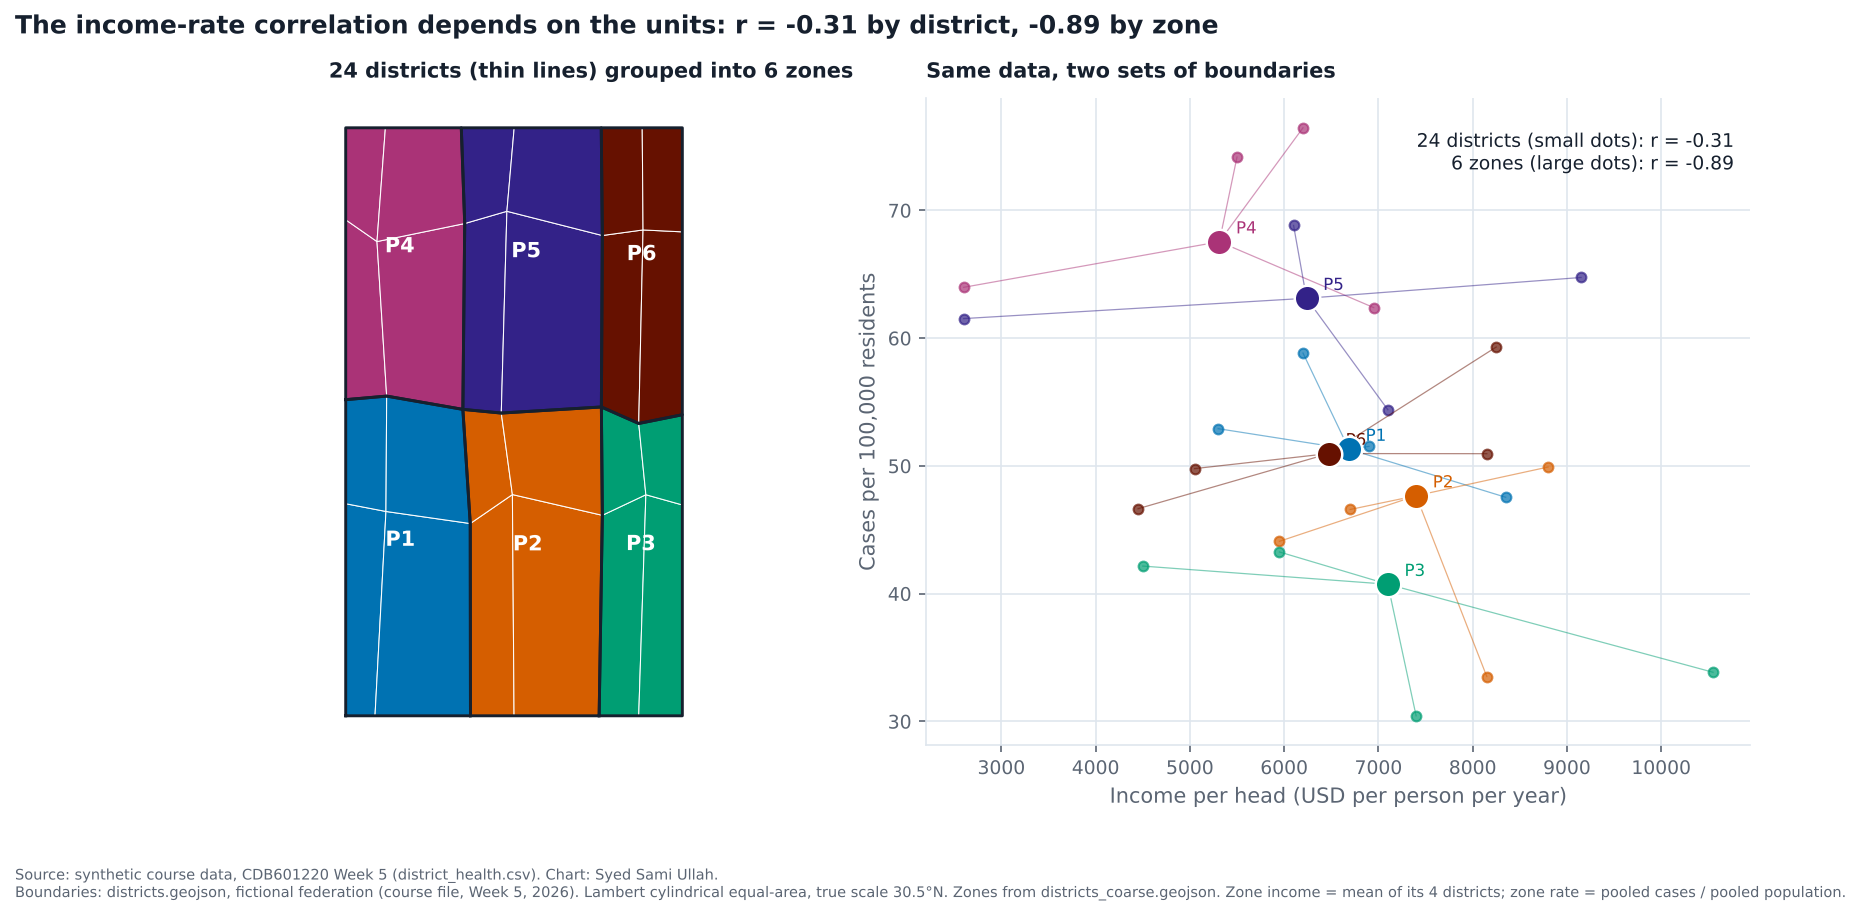

In [22]:
fig, (ax0, ax) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [0.8, 1.2]})
zone_cols = dict(zip(sorted(members), [BLUE, ORANGE, GREEN, "#AA3377", "#332288", "#661100"]))
gl.outlines(ax0, FEATS, color="white", lw=0.5, facecolor=[zone_cols[dh.set_index("code").loc[f["code"], "zone"]] for f in FEATS])
for f in coarse:                          # zone outlines in the SAME projection reference as the districts
    zx, zy = gl.equal_area_xy([p[0] for p in f["ring"]], [p[1] for p in f["ring"]], lat_ts=LAT_TS)
    ax0.plot(np.append(zx, zx[0]), np.append(zy, zy[0]), color=INK, lw=1.4)
    ax0.annotate(f["code"], gl.equal_area_xy(*gl.representative_point(f["ring"]), lat_ts=LAT_TS), ha="center",
                 color="white", fontweight="bold", fontsize=10)
ax0.set_title("24 districts (thin lines) grouped into 6 zones", fontsize=10)
for z, m in members.items():
    d = dh.set_index("code").loc[m]
    for _, rr in d.iterrows():
        ax.plot([rr.income_pc_usd, zone.loc[z, "income"]], [rr.rate, zone.loc[z, "rate"]], color=zone_cols[z], lw=0.6, alpha=0.5)
    ax.scatter(d.income_pc_usd, d.rate, s=22, color=zone_cols[z], alpha=0.7)
    ax.scatter(zone.loc[z, "income"], zone.loc[z, "rate"], s=150, color=zone_cols[z], edgecolor="white", linewidth=1.2, zorder=4)
    ax.annotate(z, (zone.loc[z, "income"], zone.loc[z, "rate"]), xytext=(8, 4), textcoords="offset points", fontsize=8, color=zone_cols[z])
ax.set_xlabel("Income per head (USD per person per year)")
ax.set_ylabel("Cases per 100,000 residents")
ax.text(0.98, 0.95, f"24 districts (small dots): r = {r7:+.2f}\n6 zones (large dots): r = {r_zone:+.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, color=INK)
ax.set_title("Same data, two sets of boundaries", fontsize=10)
fig.suptitle(f"The income-rate correlation depends on the units: r = {r7:.2f} by district, {r_zone:.2f} by zone",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save(fig, "partA_case07_redesign.png", "district_health.csv",
     BOUNDS + " Zones from districts_coarse.geojson. Zone income = mean of its 4 districts; zone rate = pooled cases / pooled population.")

**What the redesign shows.** Both scales on one chart, with lines tying each district to its zone. Grouped into zones, the noise inside each zone averages out and the slope looks steep. The honest statement is both numbers together, each with its unit.

---
## Case 8 · "This is a rural outbreak - look how much of the map is dark"
Recipe: choropleth of the rate, five natural breaks, then describe the map by how much of it is in the top two classes.

five most populous ['D17', 'D09', 'D24', 'D13', 'D11']: 12.6% of land, 59.9% of people


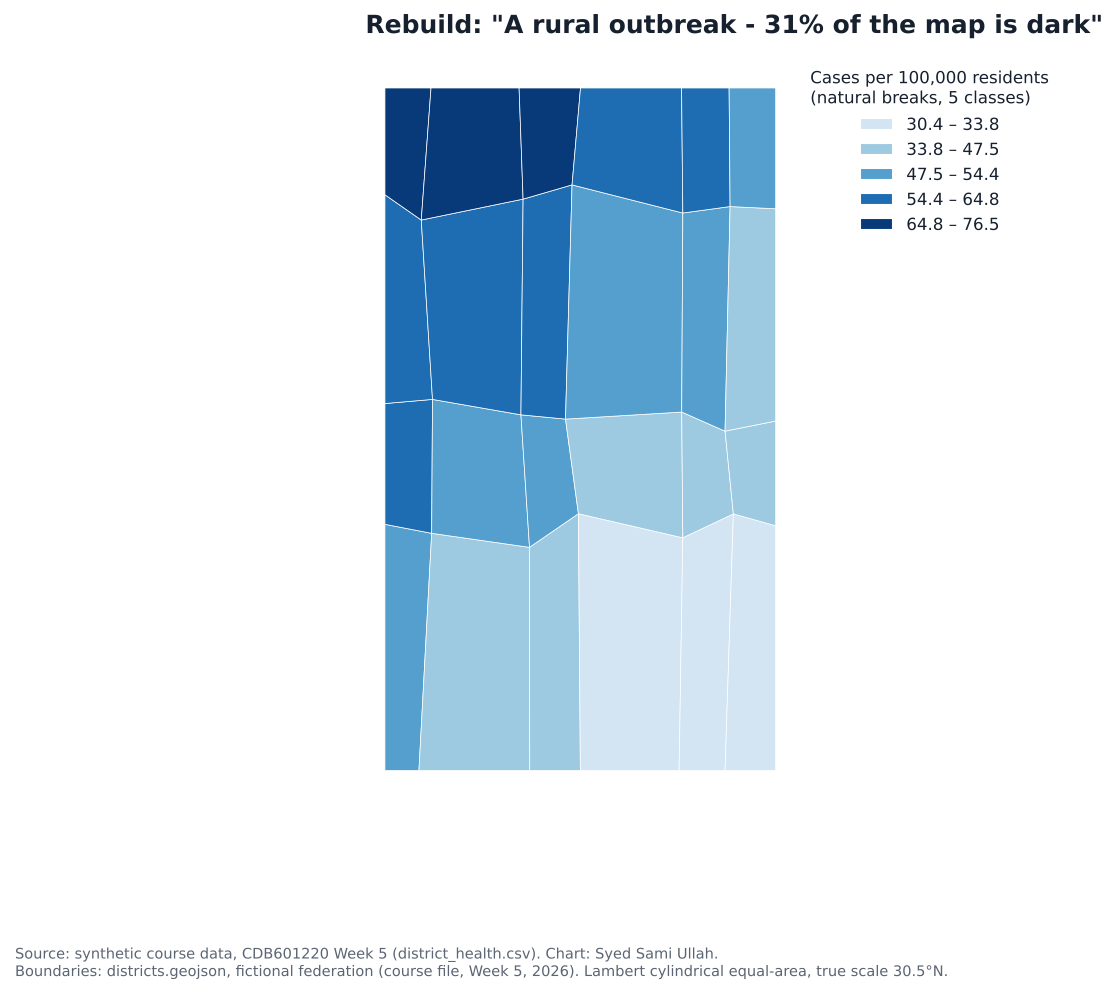

top two classes: 9 districts, 31.2% of the land, 26.5% of the people, 33.0% of the cases


In [23]:
t5 = dh.nlargest(5, "population")
a5, p5 = t5.area_km2.sum() / dh.area_km2.sum(), t5.population.sum() / dh.population.sum()
assert round(a5 * 100, 1) == 12.6 and round(p5 * 100, 1) == 59.9
print(f"five most populous {t5.code.tolist()}: {a5:.1%} of land, {p5:.1%} of people")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
e8 = gl.choropleth(ax, FEATS, dict(zip(dh.code, dh.rate)), "natural", 5,
                   legend_title="Cases per 100,000 residents\n(natural breaks, 5 classes)", fmt="{:.1f}")
dh["cls"] = gl.class_of(dh.rate, e8)
top2 = dh.cls >= 3
ax.set_title(f'Rebuild: "A rural outbreak - {dh.area_km2[top2].sum() / dh.area_km2.sum():.0%} of the map is dark"')
save(fig, "partA_case08_rebuild.png", "district_health.csv", BOUNDS)
print(f"top two classes: {top2.sum()} districts, {dh.area_km2[top2].sum() / dh.area_km2.sum():.1%} of the land, "
      f"{dh.population[top2].sum() / dh.population.sum():.1%} of the people, {dh.cases[top2].sum() / dh.cases.sum():.1%} of the cases")

**What this chart shows.** The whole northern band and some of the middle are dark, and big pale districts fill the south. The eye reads "lots of dark land", and the dark land is the sparse part of the country.

In [24]:
dh["density"] = dh.population / dh.area_km2
print(f"density of the top-two-class districts: median {dh.density[top2].median():.0f} people/km² vs {dh.density[~top2].median():.0f} for the rest")
print(f"r(rate, density) = {dh.rate.corr(dh.density):+.3f}, r(rate, log density) = {dh.rate.corr(np.log(dh.density)):+.3f}")
lo_d = dh[dh.density <= dh.density.median()]
hi_d = dh[dh.density > dh.density.median()]
print(f"pooled rate, 12 least dense districts: {lo_d.cases.sum() / lo_d.population.sum() * 1e5:.1f}; "
      f"12 most dense: {hi_d.cases.sum() / hi_d.population.sum() * 1e5:.1f} per 100k")
print(f"the five most populous hold {t5.cases.sum() / dh.cases.sum():.1%} of all cases; their rates: {t5.rate.round(1).tolist()}")
lat_mid = np.array([gl.representative_point(f["ring"])[1] for f in FEATS])
print(f"Mercator would inflate area by {1 / np.cos(np.radians(lat_mid.min())) ** 2:.2f}x (south) to {1 / np.cos(np.radians(lat_mid.max())) ** 2:.2f}x (north)")

density of the top-two-class districts: median 30 people/km² vs 39 for the rest
r(rate, density) = +0.001, r(rate, log density) = +0.137
pooled rate, 12 least dense districts: 52.0; 12 most dense: 53.0 per 100k
the five most populous hold 58.9% of all cases; their rates: [51.0, 49.9, 49.8, 64.0, 43.3]
Mercator would inflate area by 1.24x (south) to 1.49x (north)


- **Conclusion it invites:** the outbreak is a rural problem, because most of the dark ink is on big, empty northern districts.
- **Decoy:** my first thought was the projection: a Mercator-style map swells the north, which is exactly where the dark districts are. Ruled out: this map is equal-area, and even Mercator would only make the north 1.49/1.24 ≈ 1.2× too big relative to the south, nowhere near enough to manufacture the picture.
- **Mechanism:** **area read as people**. A choropleth gives each district ink in proportion to its land, but the rate is about residents. The five most populous districts are 12.6% of the land and 59.9% of the people (58.9% of the cases), so most of the epidemic is drawn as small patches. And the "rural" reading fails on the numbers: r(rate, density) = +0.00, and the 12 least dense districts run at 52.0 per 100,000 against 53.0 for the 12 most dense. The dark classes cover 31% of the land and hold 26% of the people, and they are dark because of their rate, not because they're rural.

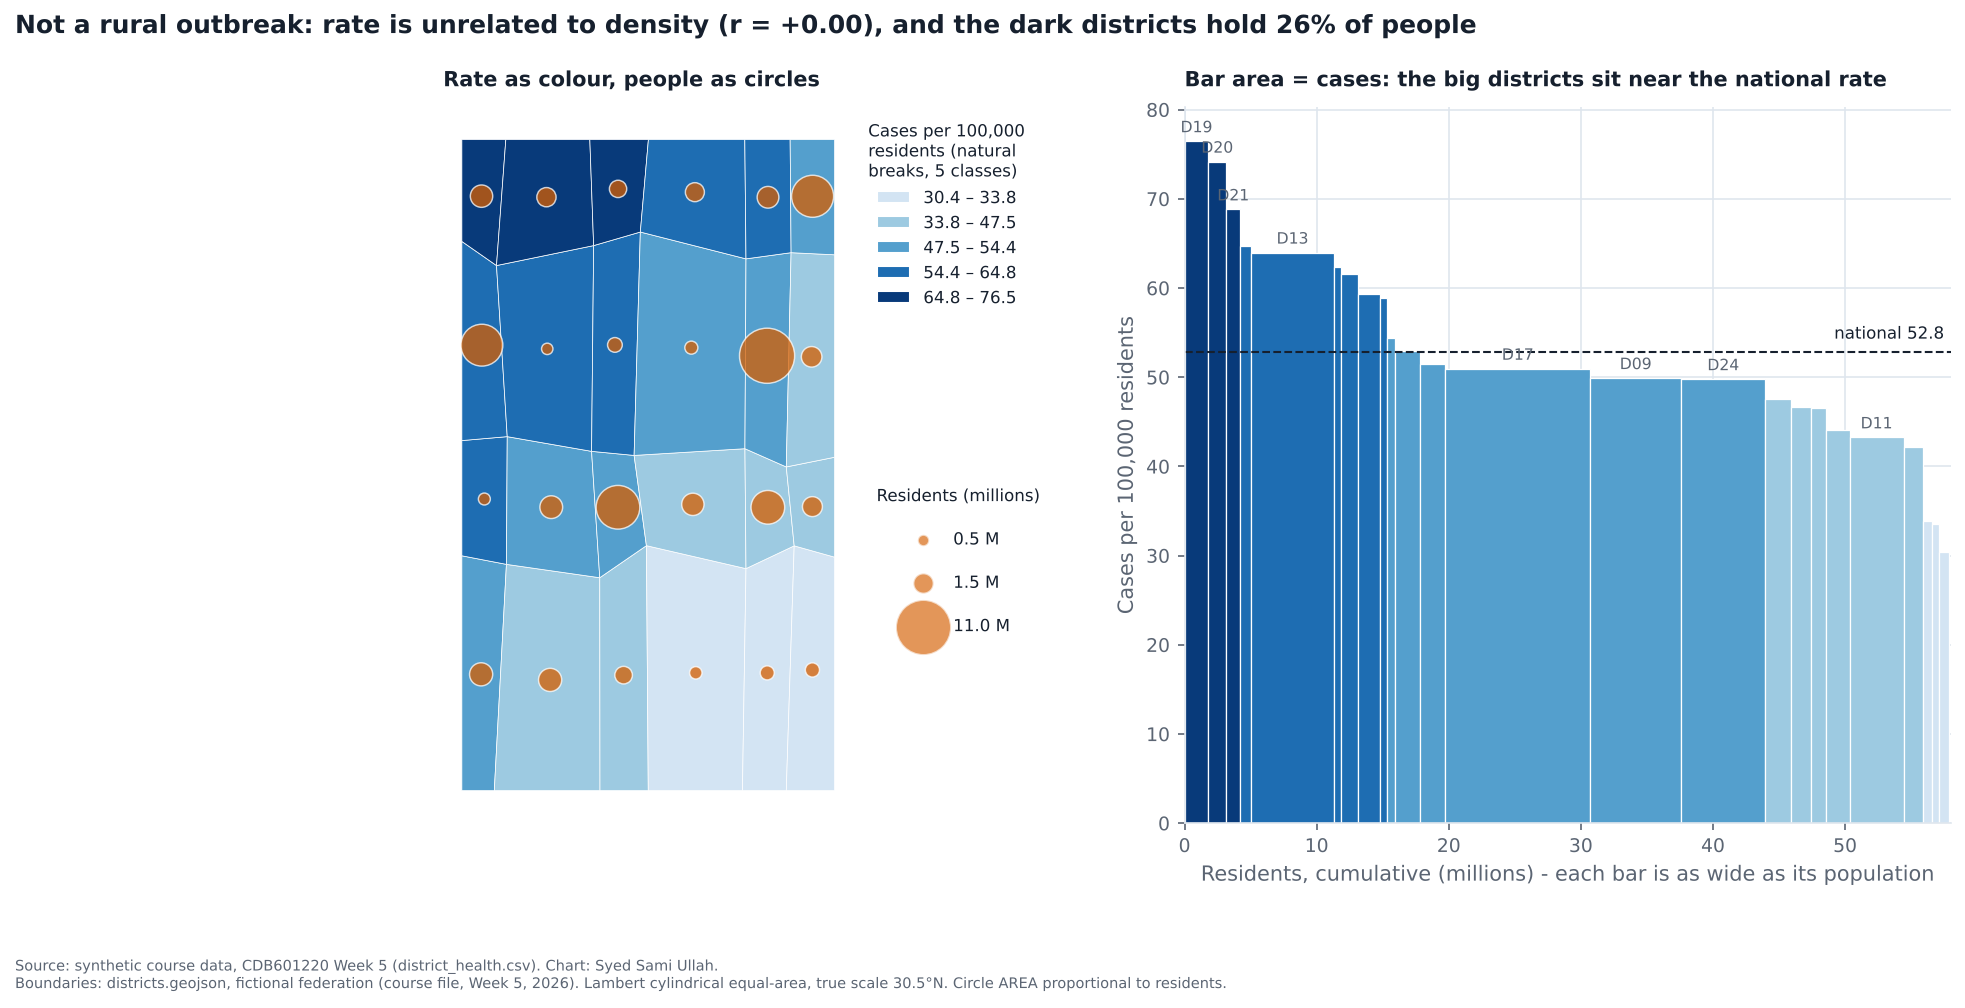

In [25]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14.5, 6.2), gridspec_kw={"width_ratios": [1.25, 1.25]})
gl.choropleth(ax, FEATS, dict(zip(dh.code, dh.rate)), "natural", 5, fmt="{:.1f}",
              legend_title="Cases per 100,000\nresidents (natural\nbreaks, 5 classes)")
ax.add_artist(ax.get_legend())
gl.prop_symbols(ax, FEATS, dict(zip(dh.code, dh.population / 1e6)), max_pt=700, color=ORANGE, alpha=0.75)
gl.size_legend(ax, (dh.population / 1e6).to_numpy(), max_pt=700, color=ORANGE, title="Residents (millions)",
               loc="upper left", bbox_to_anchor=(1.0, 0.5), fmt="{:.1f} M")
ax.set_title("Rate as colour, people as circles", fontsize=10)
srt8 = dh.sort_values("rate", ascending=False).reset_index(drop=True)
cm = plt.get_cmap(PALETTE["sequential"])
shade = [cm(0.18 + 0.78 * c / 4) for c in range(5)]
left = np.concatenate([[0], np.cumsum(srt8.population / 1e6)[:-1]])
ax2.bar(left, srt8.rate, width=srt8.population / 1e6, align="edge", color=[shade[c] for c in srt8.cls], edgecolor="white", linewidth=0.6)
for _, rr in srt8.iterrows():
    if rr.population > 3e6 or rr.code in ("D19", "D20", "D21"):
        ax2.text(left[_] + rr.population / 2e6, rr.rate + 1, rr.code, ha="center", fontsize=7.5, color=SOFT)
ax2.axhline(pooled, color=INK, lw=1, ls="--")
ax2.text(57.5, pooled + 1.5, f"national {pooled:.1f}", ha="right", fontsize=8, color=INK)
ax2.set_xlim(0, 58)
ax2.set_xlabel("Residents, cumulative (millions) - each bar is as wide as its population")
ax2.set_ylabel("Cases per 100,000 residents")
ax2.set_title("Bar area = cases: the big districts sit near the national rate", fontsize=10)
fig.suptitle("Not a rural outbreak: rate is unrelated to density (r = +0.00), and the dark districts hold 26% of people",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save(fig, "partA_case08_redesign.png", "district_health.csv", BOUNDS + " Circle AREA proportional to residents.")

**What the redesign shows.** With the people put back (circles on the map, bar widths on the right), the epidemic's weight is in the five big districts near the national rate. The high-rate districts are the thin bars on the left: real, worth a look, but a small share of the people.

---
## Case 9 · "Region A is the stronger of the two - its profile encloses visibly more area"
Recipe: radar chart, six axes in file order, both profiles on one pair of axes, filled. Compare the enclosed areas.

means 62.3 vs 62.0 (diff 0.33); enclosed areas 9,933 vs 9,433 (+5.3%)


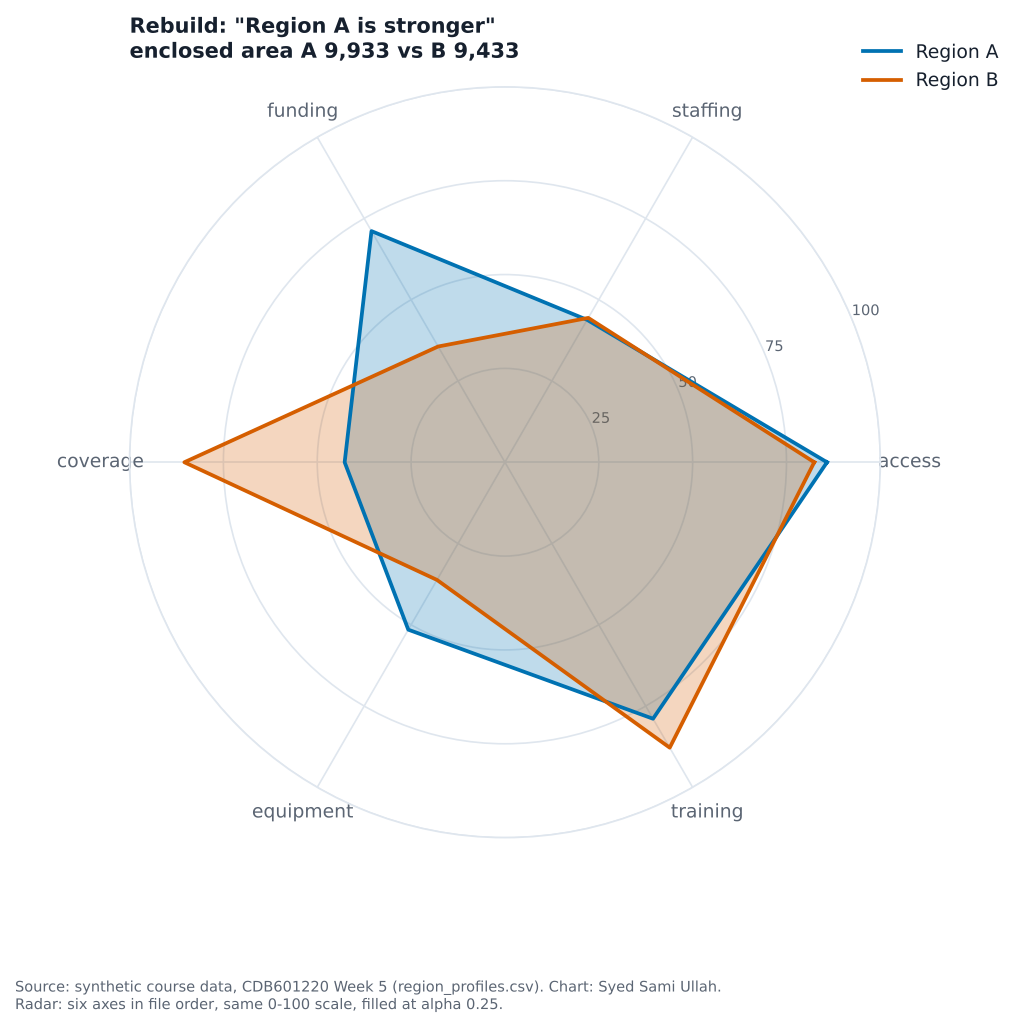

In [26]:
rp = pd.read_csv(DATA / "region_profiles.csv")


def radar_area(v):
    v = np.asarray(v, dtype=float)
    return 0.5 * np.sin(2 * np.pi / len(v)) * np.sum(v * np.roll(v, -1))


mA, mB = rp.region_a.mean(), rp.region_b.mean()
aA, aB = radar_area(rp.region_a), radar_area(rp.region_b)
assert round(mA, 1) == 62.3 and round(mB, 1) == 62.0 and round(mA - mB, 2) == 0.33
assert round(aA) == 9_933 and round(aB) == 9_433
print(f"means {mA:.1f} vs {mB:.1f} (diff {mA - mB:.2f}); enclosed areas {aA:,.0f} vs {aB:,.0f} ({aA / aB - 1:+.1%})")


def radar(ax, order, title):
    ang = np.linspace(0, 2 * np.pi, len(order), endpoint=False)
    for col, colr, lab in [("region_a", BLUE, "Region A"), ("region_b", ORANGE, "Region B")]:
        v = rp.set_index("indicator").loc[order, col].to_numpy()
        ax.plot(np.append(ang, ang[0]), np.append(v, v[0]), color=colr, lw=1.8, label=lab)
        ax.fill(np.append(ang, ang[0]), np.append(v, v[0]), color=colr, alpha=0.25)
    ax.set_xticks(ang)
    ax.set_xticklabels(order, fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_yticks([25, 50, 75, 100])
    ax.tick_params(axis="y", labelsize=7)
    ax.set_title(title, fontsize=10, pad=14)


fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw={"projection": "polar"})
radar(ax, rp.indicator.tolist(), f'Rebuild: "Region A is stronger"\nenclosed area A {aA:,.0f} vs B {aB:,.0f}')
ax.legend(loc="upper right", bbox_to_anchor=(1.18, 1.08))
save(fig, "partA_case09_rebuild.png", "region_profiles.csv", "Radar: six axes in file order, same 0-100 scale, filled at alpha 0.25.")

**What this chart shows.** Blue (A) wraps around a bit more than orange (B), and with the fill it looks like A is the bigger, stronger shape. Each region has three spikes.

In [27]:
orders = []
for perm in itertools.permutations(range(1, 6)):
    o = [0] + list(perm)
    if o[1] < o[-1]:                                  # one direction only: 5!/2 = 60 distinct orders
        v = rp.iloc[o]
        orders.append((v.indicator.tolist(), radar_area(v.region_a), radar_area(v.region_b)))
diff = np.array([a - b for _, a, b in orders])
flip = min(orders, key=lambda t: t[1] - t[2])
lead = (rp.region_a > rp.region_b)
print(f"distinct axis orders: {len(orders)}; A encloses more in {(diff > 0).sum()}, B in {(diff < 0).sum()}")
print(f"area difference A - B ranges {diff.min():+,.0f} to {diff.max():+,.0f}")
print(f"an order where B wins: {flip[0]} -> A {flip[1]:,.0f}, B {flip[2]:,.0f}")
print(f"A leads on {lead.sum()} indicators {rp.indicator[lead].tolist()}, B on {(~lead).sum()} {rp.indicator[~lead].tolist()}")
print(rp.assign(gap=rp.region_a - rp.region_b).to_string(index=False))

distinct axis orders: 60; A encloses more in 39, B in 21
area difference A - B ranges -1,131 to +1,659
an order where B wins: ['access', 'staffing', 'funding', 'equipment', 'training', 'coverage'] -> A 9,366, B 10,497
A leads on 3 indicators ['access', 'funding', 'equipment'], B on 3 ['staffing', 'coverage', 'training']
indicator  region_a  region_b   gap
   access      85.8      82.4   3.4
 staffing      43.8      44.4  -0.6
  funding      71.1      35.6  35.5
 coverage      42.7      85.4 -42.7
equipment      51.5      36.2  15.3
 training      78.9      87.8  -8.9


- **Conclusion it invites:** Region A performs better overall, because its shape is bigger.
- **Decoy:** my first thought was that A really is a bit better on average. Ruled out: the means are 62.3 and 62.0, a gap of 0.33 on a 0-100 scale, and A leads on 3 indicators while B leads on the other 3. Small gaps on some and big gaps both ways on the others (funding +35.5 for A, coverage +42.7 for B).
- **Mechanism:** the **enclosed area** of a radar polygon is ½·sin(60°)·Σ vᵢ·vᵢ₊₁, a sum of products of *neighbouring* values. So it depends on which indicators sit next to each other, which is just the file order. A's two strengths (access, training) happen to sit beside each other through the wrap-around. Across the 60 distinct axis orders, A encloses more in 39 and B in 21, and the gap swings from −1,131 to +1,659. In the order access, staffing, funding, equipment, training, coverage, B wins 10,497 to 9,366.

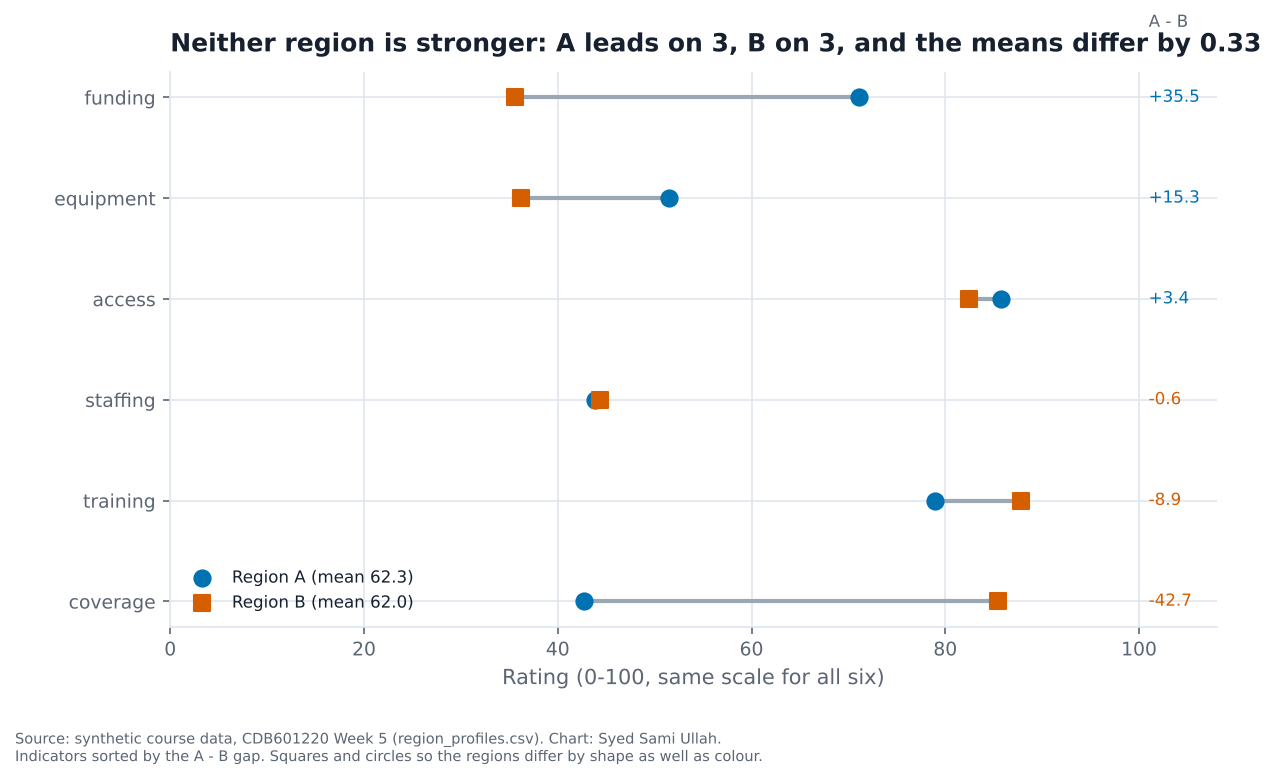

In [28]:
d9 = rp.assign(gap=rp.region_a - rp.region_b).sort_values("gap")
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(d9))
ax.hlines(y, d9[["region_a", "region_b"]].min(axis=1), d9[["region_a", "region_b"]].max(axis=1), color=GREY, lw=2)
ax.scatter(d9.region_a, y, s=60, color=BLUE, zorder=3, label=f"Region A (mean {mA:.1f})")
ax.scatter(d9.region_b, y, s=60, color=ORANGE, marker="s", zorder=3, label=f"Region B (mean {mB:.1f})")
for yy, (_, rr) in zip(y, d9.iterrows()):
    ax.text(101, yy, f"{rr.gap:+.1f}", va="center", fontsize=8, color=BLUE if rr.gap > 0 else ORANGE)
ax.text(101, len(d9) - 0.3, "A - B", fontsize=8, color=SOFT)
ax.set_yticks(y)
ax.set_yticklabels(d9.indicator)
ax.set_xlim(0, 108)
ax.set_xlabel("Rating (0-100, same scale for all six)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Neither region is stronger: A leads on 3, B on 3, and the means differ by 0.33")
save(fig, "partA_case09_redesign.png", "region_profiles.csv", "Indicators sorted by the A - B gap. Squares and circles so the regions differ by shape as well as colour.")

**What the redesign shows.** Laid out as a dot plot, position carries the values and nothing depends on axis order. A is far ahead on funding and equipment, B is far ahead on coverage and training, and overall they're level.

---
## The two cases fixed without changing the chart type
**Case 3 and case 4.** Both redesigns are still parallel coordinates plots of the same 60 lines. Case 3 changes only the scaling (log10 before min-max), case 4 changes only the axis order (greedy chain by |r|). Case 5 keeps its map too, but the fix there is to stop pretending there are five levels, so I added a strip of intervals beside it.